# Group Assignment: Prediction in Bioinformatics

**Fundamentals of Health Data Science**

In the individual assignment you followed a guided path. **This time there is no path: your group designs it.**

Your group has been allocated **one** of three problems:

| | Problem | Question |
|---|---|---|
| **A** | Antimicrobial resistance from bacterial genomes | Is this *E. coli* isolate resistant to ciprofloxacin? |
| **B** | Blood gene expression to detect active TB | Does this patient have active TB? |
| **C** | Malaria parasites that clear slowly | Will this infection clear slowly after artemisinin treatment? |

Before you start, read your problem's section in **Group Assignment: the three problems and their data dictionaries**.

> All datasets are **simulated for teaching**. No real patients or isolates are included.

### Rules: read before you start

**Group work**
- One notebook per group. Everyone in the group is responsible for **all** of it.
- Every member must be able to **explain and defend any part** of the notebook, not only the part they led.
- Any member may be asked to complete a **short timed test or oral check** on any part of the notebook.

**Use of AI tools**
- Your plan, your decisions and your conclusions must be **in your own words. Do not use AI tools to write them.**
- **Any use of AI tools must be stated** in each member's declaration: what it was used for, and where.

**Deadline:** **Monday 16 November 2026**. You may submit earlier. **How it is marked:** details will be shared separately.

**What you hand in:** this notebook, run from top to bottom (*Restart and run all*), with the contribution statement and every member's declaration completed. Name the file with your group number and problem, e.g. `G03_ProblemC.ipynb`.

---
## 1. Your group and your data (PROVIDED)

Fill in the three settings, then run the cell.
- `MEMBERS`: every member's registration number, **exactly as on the class list**. For a group of two, leave the third as `""`.
- `GROUP_ID`: your group number from the allocation list, e.g. `"G03"`.
- `PROBLEM`: your allocated problem: `"A"`, `"B"` or `"C"`.

Keep your problem's data file in the same folder as this notebook (on Google Colab, the cell will ask you to upload it). **Write the group fingerprint into every member's declaration.**

In [1]:
# ===================== PROVIDED CELL: fill in the three settings, do not edit the rest =====================
MEMBERS = ["2026/HD07/23463X", "2026/HD07/23484U", "2026/HD07/23443U"]   # registration numbers, exactly as on the class list
GROUP_ID = "G06"                 # e.g. "G03"
PROBLEM = "C"                   # "A", "B" or "C"

import os, hashlib
import numpy as np
import pandas as pd

FILES = {"A": "problemA_ecoli_cipro_genomes.csv", "B": "problemB_tb_blood_expression.csv", "C": "problemC_malaria_clearance.csv"}
ID_COLUMN = {"A": "isolate_id", "B": "sample_id", "C": "patient_id"}
SAMPLE_SIZE = {"A": 2000, "B": 1500, "C": 2500}
OUTCOME = {"A": "cipro_resistant", "B": "active_tb", "C": "slow_clearance"}

members = sorted(m.strip().upper().replace(" ", "") for m in MEMBERS if m.strip())
problem = PROBLEM.strip().upper()
if not 2 <= len(members) <= 3:
    raise ValueError("Type the registration numbers of all 2 or 3 group members in MEMBERS.")
if len(set(members)) < len(members):
    raise ValueError("The same registration number is typed twice in MEMBERS.")
if problem not in FILES:
    raise ValueError('Set PROBLEM to "A", "B" or "C" (your allocated problem).')
if not GROUP_ID.strip():
    raise ValueError('Set GROUP_ID to your group number from the allocation list, e.g. "G03".')

DATA_FILE = FILES[problem]
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files          # only on Google Colab
        print(f"Please upload {DATA_FILE}"); files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {DATA_FILE} in the same folder as this notebook.")

GROUP_SEED = int(hashlib.sha256(("|".join(members) + "|" + problem).encode()).hexdigest(), 16) % (2**31)
SPLIT_SEED = GROUP_SEED % 10000

everyone = pd.read_csv(DATA_FILE)
all_ids = np.sort(everyone[ID_COLUMN[problem]].unique())
our_ids = np.random.default_rng(GROUP_SEED).choice(all_ids, SAMPLE_SIZE[problem], replace=False)
our_data = (everyone[everyone[ID_COLUMN[problem]].isin(our_ids)]
            .sample(frac=1, random_state=SPLIT_SEED).reset_index(drop=True))

fp = hashlib.sha256(",".join(sorted(our_ids)).encode()).hexdigest()[:8].upper()
GROUP_FINGERPRINT = fp[:4] + "-" + fp[4:]

print(f"Group {GROUP_ID.strip().upper()} | Problem {problem} | members: {', '.join(members)}")
print(f"Group fingerprint : {GROUP_FINGERPRINT}   <- write this in every member's declaration")
print(f"SPLIT_SEED        : {SPLIT_SEED}   <- use random_state=SPLIT_SEED whenever you shuffle or split")
print(f"Your data         : {our_data.shape[0]} rows, {our_data.shape[1]} columns, in a table called our_data")
print(f"Outcome column    : {OUTCOME[problem]}")

Group G06 | Problem C | members: 2026/HD07/23443U, 2026/HD07/23463X, 2026/HD07/23484U
Group fingerprint : 98C9-85DA   <- write this in every member's declaration
SPLIT_SEED        : 482   <- use random_state=SPLIT_SEED whenever you shuffle or split
Your data         : 2553 rows, 13 columns, in a table called our_data
Outcome column    : slow_clearance


## 2. Libraries

A starting set. Add any others you need, here at the top.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, recall_score, precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay
import joblib

---
## 3. Expected stages

A modelling project usually passes through these stages. **You may add, merge, re-order or skip stages**, as long as your plan explains why.

1. Understand the problem and the data dictionary (who will use the model, and when?)
2. First look at the data, and cleaning rules
3. Leakage check (what is known at the moment of prediction?)
4. Train/test split
5. Exploration, on the training data only
6. A baseline model
7. Feature work: transformations, interactions, encoding, choice of columns
8. Pipeline and cross-validation
9. The outcome rate, and the choice of cut-off (if relevant to your problem)
10. Overfitting check and tuning
11. Final test, once
12. Save the model, write a model card, and answer the question

> Your problem has **at least one challenge you have not met in the demonstration notebook**. Look for it in the data dictionary and in your exploration.

---
## 4. Your plan (complete before you write any code)

For each stage you will carry out, say **what** you will do, **why**, and **who leads** it. You may update the plan as you go: if you change it, add a line saying what changed and why.

| Stage | What we will do | Why | Led by |
|---|---|---|---|
| Stage 1 | Understand the problem and the data dictionary | To gain more understanding of the problem: who will use the model and when they will use it, since every later choice depends on this | Aheebwa |
| Stage 2 | Look at the data, run validity checks and assign cleaning rules | To check for issues with our data and how best we can improve our data set, since the data dictionary warns that the file has mistakes | Aheebwa |
| Stage 3 | Check for leakage | To prevent our model from looking excellent when tested but being useless in practice, by keeping out anything not known at enrolment | Aheebwa |
| Stage 4 | Split the data into stratified train and test sets | We want to know how the model performs on patients it has never seen, so the test set is locked away and used only once | Aheebwa |
| Stage 5 | Exploration on the training data only, including interactions | To answer how common the outcome is, and the relationship and shape of the data. This guides us to the feature work | Hilda |
| Stage 6 | Design the baseline model | A baseline is the simplest sensible model. It answers how far we get without any cleverness, and gives each feature work a reference point | Hilda |
| Stages 7 and 8 | Feature engineering (interaction, choice of columns, encoding), then pipeline design and cross-validation | To build new columns that present the information in a form the model can use, each new feature answering something seen in the exploration, and to keep all preparation inside a pipeline so that cross-validation stays honest | Hilda |
| Stage 10 | Overfitting check and tuning | To prevent a model that learns the quirks of its training data so well that it scores well on the training data and worse on new data. C is settled here, before the cut-off | Jallow |
| Stage 9 | Set the cut-off, looking at the outcome rate, recall and precision | The model outputs a probability. To act, someone must decide above what probability we flag, based on the outcome rate and the performance (recall and precision) | Jallow |
| Stage 11 | Perform the final test, only once | Every decision is now fixed: cleaning rules, features, C and cut-off. The test set is opened only now. Its patients played no part in any choice, so the result is an honest estimate of performance on new patients. If we looked at the result and then went back to improve the model, the test set would become part of training and its result would no longer be honest | Jallow |
| Stage 12 | Save the model, and write the model card | A model that lives only inside a notebook cannot be used by anyone. Saving it to a file lets someone else load it and make predictions, and the model card tells them what it is for and its limits | Jallow |

**What we think the main challenge in our problem is:**

There are several candidates for the main problem, and we think the main one is the genotype (kelch13) column in the original data frame. It has 25 labels, several spellings of wild_type and very rare values. On top of that, the effect of genotype depends on age, the place (district) is tangled up with genotype, and more than half of slow clearers carry wild-type parasites, which limits what any enrolment model can find.

All this is tangled up in one column, which makes it a major problem in data cleaning, exploration and model design. Hence it is a major challenge we haven't encountered before.

**Changes to the plan as we went (and why):**
- Stages 7 and 8 were combined because they move hand in hand and complement each other.
- Stage 10 came before the cut-off (stage 9) because changing C changes the predicted probabilities that the cut-off is applied to, so it has to be settled before the cut-off is chosen.

---
## 5. Your work

Add as many cells as you need. For each stage, a short markdown cell with **Where we are · Why this step · What we do · What we decided** (as in the demonstration notebook) makes your reasoning easy to follow and to mark.

### Stage 1. Understand the problem and the data dictionary

**Where we are:** At the start, before looking at any of the data values.

**Why this step:** To gain more understanding of the problem: who will use the model and when they will use it. Every later choice depends on this, from which columns we can use to where we put the cut-off.

**Who will use the model, and when is the prediction made?**
- The user is the national malaria control programme. They want to know where and in whom resistance is emerging. They are not deciding how to treat one patient.
- The prediction is made at enrolment, before the first dose of artemether-lumefantrine. So the model can only use what is recorded at enrolment or from the enrolment blood sample.
- The outcome is slow_clearance, meaning a clearance half-life longer than 5 hours. It is calculated from blood films taken over several days, so it cannot be known at enrolment. That is why a prediction is useful.
- A flag would lead to something fairly cheap, like sending the sample for sequencing or watching a site or age group more closely. This matters for the cut-off in Stage 9.

**What we decided:** We predict slow clearance at enrolment using patient information and the parasite genotype only. We judge the model on how well it picks out slow clearers, and on whether it can show where and in whom the risk is highest.

### Stage 2. First look at the data, and cleaning rules

**Where we are:** We have our_data from the provided cell. It has 2,553 rows and 13 columns, even though 2,500 patients were drawn.

**Why this step:** To check for issues with our data and how best we can improve our data set. The data dictionary warns that the file has mistakes, so we find each one and give it a written rule before any modelling.

**What we do:** We check the shape, the column types, the missing values and the value ranges against the data dictionary, then look at the odd rows themselves.

**What we decided:** We found seven problems. Our rule for each:

| Problem in our sample | Count | Rule | Reason |
|---|---|---|---|
| Exact duplicate rows | 53 | Remove | Every repeat matched its original in all columns. If left in, one copy could land in training and the other in the test set |
| Wild type spelt four ways (WT, wildtype, Wild type) | 144 | Change to wild_type | They are the same genotype |
| Haemoglobin above 18 g/dL (93 to 106) | 5 | Divide by 10 | Divided by 10 they become 9.3 to 10.6, which is normal for these patients. Most likely g/L was typed into a g/dL column |
| Parasite density of 0 | 7 | Set to missing, impute later | Every enrolled patient must have parasites, so the value is wrong but the rest of the row is fine. Log10 of 0 also cannot be calculated |
| Parasite density exactly 500,000 | 19 | Keep | Most likely the upper counting limit. These patients really do have very high density, and on a log scale the cap changes little |
| Weight missing | 87 (84 after duplicates removed) | Median, inside the pipeline | The median is learned from the data, so it must come from training rows only |
| Haemoglobin missing | 59 | Median, inside the pipeline | Same reason |

These rules look at one row at a time and learn nothing from other patients, so it is safe to apply them before the split. After cleaning we have 2,500 rows, one per patient, and 22 kelch13 labels.

In [3]:
# How big is our sample, and what does one row look like?
print("Rows and columns:", our_data.shape)
our_data.head(8)

Rows and columns: (2553, 13)


,patient_id,district,age_years,sex,weight_kg,fever_days_before,haemoglobin_g_dL,baseline_parasites_per_uL,kelch13,crt_K76T,mdr1_N86Y,day3_positive,slow_clearance
0,MAL34219,Busia,8.8,F,28.9,3,9.5,6617.0,wild_type,0,0,1,1
1,MAL30228,Busia,4.6,M,16.1,3,11.6,31733.0,wild_type,0,0,0,0
2,MAL31515,Kabarole,3.9,M,11.9,3,11.4,12086.0,wild_type,0,0,0,0
3,MAL30143,Agago,2.9,F,10.9,3,12.2,20229.0,wild_type,0,1,0,0
4,MAL31312,Mubende,9.4,M,29.5,4,9.8,20516.0,wild_type,1,0,0,0
5,MAL34532,Tororo,6.5,F,21.4,4,12.6,6900.0,Wild type,0,0,0,0
6,MAL33351,Tororo,11.3,M,31.0,2,14.5,11078.0,A578S,0,0,0,0
7,MAL35306,Agago,13.6,M,42.0,6,9.9,1753.0,A578S,1,0,0,0


In [4]:
# Column types and how many values are present in each column
our_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2553 entries, 0 to 2552
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 2553 non-null   str    
 1   district                   2553 non-null   str    
 2   age_years                  2553 non-null   float64
 3   sex                        2553 non-null   str    
 4   weight_kg                  2466 non-null   float64
 5   fever_days_before          2553 non-null   int64  
 6   haemoglobin_g_dL           2494 non-null   float64
 7   baseline_parasites_per_uL  2553 non-null   float64
 8   kelch13                    2553 non-null   str    
 9   crt_K76T                   2553 non-null   int64  
 10  mdr1_N86Y                  2553 non-null   int64  
 11  day3_positive              2553 non-null   int64  
 12  slow_clearance             2553 non-null   int64  
dtypes: float64(4), int64(5), str(4)
memory usage: 259.4 KB


In [5]:
# Summary of the numeric columns: compare min and max with the valid ranges in the data dictionary
our_data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age_years,2553.0,9.64,8.59,0.5,4.1,7.1,12.1,70.0
weight_kg,2466.0,27.18,17.39,4.7,14.1,21.9,34.7,87.4
fever_days_before,2553.0,3.46,1.57,1.0,2.0,3.0,4.0,10.0
haemoglobin_g_dL,2494.0,11.00,4.44,5.6,9.6,10.8,12.0,106.0
baseline_parasites_per_uL,2553.0,33256.90,66356.08,0.0,4437.0,11738.0,31819.0,500000.0
crt_K76T,2553.0,0.17,0.38,0.0,0.0,0.0,0.0,1.0
mdr1_N86Y,2553.0,0.21,0.41,0.0,0.0,0.0,0.0,1.0
day3_positive,2553.0,0.13,0.34,0.0,0.0,0.0,0.0,1.0
slow_clearance,2553.0,0.12,0.32,0.0,0.0,0.0,0.0,1.0


In [6]:
# Every value that appears in the text columns, with its count
for col in ["district", "sex", "kelch13"]:
    print(f"\n{col}: {our_data[col].nunique()} different values")
    print(our_data[col].value_counts().to_string())


district: 8 different values
district
Tororo      374
Agago       373
Mubende     351
Kabarole    338
Busia       333
Kitgum      265
Hoima       260
Lamwo       259

sex: 2 different values
sex
F    1331
M    1222

kelch13: 25 different values
kelch13
wild_type    1871
A578S         127
C469Y         101
WT             72
A675V          55
wildtype       51
P441L          43
K189T          40
R561H          34
R622I          22
Wild type      21
A481V          21
R515K          20
C469F          17
C580Y          15
G449A          11
P574L           7
P527H           6
N458Y           6
F446I           6
M476I           3
Y493H           1
R539T           1
I543T           1
P553L           1


In [7]:
# Count each kind of problem, using the valid ranges from the data dictionary
no_exact_copies = our_data.drop_duplicates()
problems = pd.Series({
    "rows in our_data": len(our_data),
    "unique patient_id": our_data["patient_id"].nunique(),
    "exact duplicate rows": our_data.duplicated().sum(),
    "same patient_id but different values": no_exact_copies["patient_id"].duplicated().sum(),
    "kelch13: wild type not spelt 'wild_type'": our_data["kelch13"].isin(["WT", "wildtype", "Wild type"]).sum(),
    "weight_kg missing": our_data["weight_kg"].isna().sum(),
    "haemoglobin_g_dL missing": our_data["haemoglobin_g_dL"].isna().sum(),
    "haemoglobin_g_dL above 18": (our_data["haemoglobin_g_dL"] > 18).sum(),
    "haemoglobin_g_dL below 3": (our_data["haemoglobin_g_dL"] < 3).sum(),
    "baseline_parasites_per_uL of 0 or less": (our_data["baseline_parasites_per_uL"] <= 0).sum(),
    "baseline_parasites_per_uL exactly 500,000": (our_data["baseline_parasites_per_uL"] == 500000).sum(),
    "age_years below 0.5": (our_data["age_years"] < 0.5).sum(),
}, name="count")
problems.to_frame()

,count
rows in our_data,2553
unique patient_id,2500
exact duplicate rows,53
same patient_id but different values,0
kelch13: wild type not spelt 'wild_type',144
weight_kg missing,87
haemoglobin_g_dL missing,59
haemoglobin_g_dL above 18,5
haemoglobin_g_dL below 3,0
baseline_parasites_per_uL of 0 or less,7


In [8]:
# Look at the suspicious rows themselves before deciding what to do with them
print("Haemoglobin above 18 g/dL:")
display(our_data.loc[our_data["haemoglobin_g_dL"] > 18,
                     ["patient_id", "age_years", "haemoglobin_g_dL", "slow_clearance"]])
print("Parasite density of 0:")
display(our_data.loc[our_data["baseline_parasites_per_uL"] <= 0,
                     ["patient_id", "age_years", "baseline_parasites_per_uL", "slow_clearance"]])
print("The ten highest parasite densities:")
print(our_data["baseline_parasites_per_uL"].sort_values(ascending=False).head(10).tolist())

Haemoglobin above 18 g/dL:


,patient_id,age_years,haemoglobin_g_dL,slow_clearance
438,MAL30900,5.2,106.0,0
489,MAL35569,5.3,98.0,0
1061,MAL35886,7.0,105.0,0
1340,MAL30427,13.2,93.0,1
2201,MAL31624,31.1,105.0,0


Parasite density of 0:


,patient_id,age_years,baseline_parasites_per_uL,slow_clearance
82,MAL33649,12.5,0.0,0
398,MAL31887,9.0,0.0,0
600,MAL31041,10.5,0.0,0
1113,MAL32469,7.6,0.0,0
1527,MAL31436,2.8,0.0,0
1917,MAL34515,11.9,0.0,0
2408,MAL30577,1.7,0.0,0


The ten highest parasite densities:
[500000.0, 500000.0, 500000.0, 500000.0, 500000.0, 500000.0, 500000.0, 500000.0, 500000.0, 500000.0]


In [9]:
# Decision 1: cleaning rules (reasons in the Stage 2 cell above)
HB_RULE = "divide_by_10"            # "divide_by_10" (treat as g/L typed by mistake) or "set_missing"
ZERO_PARASITE_RULE = "set_missing"  # "set_missing" (impute later, inside the pipeline) or "drop_rows"
CAP_500K_RULE = "keep"              # "keep" (treat 500,000 as a real upper limit) or "set_missing"

In [10]:
WILD_TYPE_SPELLINGS = ["wild_type", "WT", "wildtype", "Wild type"]

def apply_cleaning_rules(df):
    """Row-by-row cleaning rules. Nothing here is learned from other rows, so it is safe before the split."""
    out = df.drop_duplicates().copy()                                          # rule 1: exact copies
    out["kelch13"] = out["kelch13"].replace(WILD_TYPE_SPELLINGS, "wild_type")  # rule 2: one spelling

    too_high = out["haemoglobin_g_dL"] > 18                                    # rule 3: impossible haemoglobin
    if HB_RULE == "divide_by_10":
        out.loc[too_high, "haemoglobin_g_dL"] = out.loc[too_high, "haemoglobin_g_dL"] / 10
    else:
        out.loc[too_high, "haemoglobin_g_dL"] = np.nan

    zero = out["baseline_parasites_per_uL"] <= 0                               # rule 4: zero parasites
    if ZERO_PARASITE_RULE == "drop_rows":
        out = out[~zero].copy()
    else:
        out.loc[zero, "baseline_parasites_per_uL"] = np.nan

    if CAP_500K_RULE == "set_missing":                                         # rule 5: the 500,000 values
        out.loc[out["baseline_parasites_per_uL"] == 500000, "baseline_parasites_per_uL"] = np.nan
    return out

clean = apply_cleaning_rules(our_data)

print(f"Rows before cleaning: {len(our_data)}   after: {len(clean)}")
print(f"Unique patients after cleaning: {clean['patient_id'].nunique()}")
print(f"kelch13 labels before: {our_data['kelch13'].nunique()}   after: {clean['kelch13'].nunique()}")
print(f"Haemoglobin range after: {clean['haemoglobin_g_dL'].min()} to {clean['haemoglobin_g_dL'].max()} g/dL")
print("Missing values after cleaning:")
print(clean.isna().sum()[clean.isna().sum() > 0].to_string())

Rows before cleaning: 2553   after: 2500
Unique patients after cleaning: 2500
kelch13 labels before: 25   after: 22
Haemoglobin range after: 5.6 to 16.0 g/dL
Missing values after cleaning:
weight_kg                    84
haemoglobin_g_dL             59
baseline_parasites_per_uL     7


### Stage 3. Leakage check

**Where we are:** The data are clean. Before splitting, we decide which columns the model is allowed to see.

**Why this step:** To prevent our model from looking excellent when tested but being useless in practice. Anything not known at enrolment has to stay out.

**What we do:** We go through the "When recorded" column of the data dictionary, one column at a time.

**What we decided:**
- day3_positive is taken out. It is recorded on day 3 of treatment, so it does not exist at enrolment. Stage 5 shows how close it is to the answer: 76.3% of the day-3 positive patients were slow clearers, against 2.5% of the day-3 negative ones, and it caught 180 of the 221 slow clearers in training.
- patient_id is taken out because it is only a label.
- The other ten columns are kept. The genotype columns come from the enrolment blood sample, so the data dictionary allows them. In real life sequencing takes days or weeks. We see that as a limit on how fast the model could be used, not as leakage.
- We use day3_positive once more at the end of Stage 11, only as a comparison. It is never a predictor.

In [11]:
# When is each column recorded? (from the data dictionary)
timing = pd.DataFrame([
    ("patient_id", "at enrolment", "no: a label, not information"),
    ("district", "at enrolment", "yes"),
    ("age_years", "at enrolment", "yes"),
    ("sex", "at enrolment", "yes"),
    ("weight_kg", "at enrolment", "yes"),
    ("fever_days_before", "at enrolment", "yes"),
    ("haemoglobin_g_dL", "at enrolment", "yes"),
    ("baseline_parasites_per_uL", "at enrolment", "yes"),
    ("kelch13", "from the enrolment blood sample", "yes"),
    ("crt_K76T", "from the enrolment blood sample", "yes"),
    ("mdr1_N86Y", "from the enrolment blood sample", "yes"),
    ("day3_positive", "on day 3 of treatment", "NO: recorded after the moment of prediction"),
    ("slow_clearance", "after the first days of treatment", "this is the outcome"),
], columns=["column", "when recorded", "can the model use it?"])
display(timing)

ID_COL = "patient_id"
TARGET = OUTCOME[problem]          # "slow_clearance", set by the provided cell
LEAKY = ["day3_positive"]

X = clean.drop(columns=[ID_COL, TARGET] + LEAKY)   # the clues
y = clean[TARGET]                                  # the answer
print("Predictor columns kept:", list(X.columns))

,column,when recorded,can the model use it?
0,patient_id,at enrolment,"no: a label, not information"
1,district,at enrolment,yes
2,age_years,at enrolment,yes
3,sex,at enrolment,yes
4,weight_kg,at enrolment,yes
5,fever_days_before,at enrolment,yes
6,haemoglobin_g_dL,at enrolment,yes
7,baseline_parasites_per_uL,at enrolment,yes
8,kelch13,from the enrolment blood sample,yes
9,crt_K76T,from the enrolment blood sample,yes


Predictor columns kept: ['district', 'age_years', 'sex', 'weight_kg', 'fever_days_before', 'haemoglobin_g_dL', 'baseline_parasites_per_uL', 'kelch13', 'crt_K76T', 'mdr1_N86Y']


### Stage 4. Train/test split

**Where we are:** We have 2,500 patients and ten allowed predictors.

**Why this step:** We want to know how the model performs on patients it has never seen. So the test set is locked away now and used only once, in Stage 11.

**What we do:** A stratified split with random_state=SPLIT_SEED (482), done after the duplicates were removed.

**What we decided:**
- We keep 25% for testing. That gives 1,875 training patients (221 slow, 11.8%) and 625 test patients (73 slow, 11.7%).
- We chose 25% and not 20% because slow clearers are few. A 20% test set would hold only about 59 of them, and the final result would be even less certain.
- Stratifying keeps the slow rate almost the same in both parts. The check found no patient in both parts.

In [12]:
# Decision 2: test size (reason in the Stage 4 cell above)
TEST_SIZE = 0.25

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SPLIT_SEED)

print(f"Training set: {len(X_train)} patients, {y_train.sum()} slow clearers ({y_train.mean():.1%})")
print(f"Test set    : {len(X_test)} patients, {y_test.sum()} slow clearers ({y_test.mean():.1%})")

# Safety check: no patient may sit in both parts
overlap = set(clean.loc[X_train.index, ID_COL]) & set(clean.loc[X_test.index, ID_COL])
print("Patients in both training and test:", len(overlap))

Training set: 1875 patients, 221 slow clearers (11.8%)
Test set    : 625 patients, 73 slow clearers (11.7%)
Patients in both training and test: 0


### Stage 5. Exploration, on the training data only

**Where we are:** We now work with the 1,875 training patients only.

**Why this step:** To answer how common the outcome is, and the relationship and shape of the data. What we find here guides us to the feature work.

**What we do:** We look at the outcome rate, the slow rate across each predictor, the shape of the numeric columns, the effect of place, and genotype and age together.

**What we decided (main findings):**
1. The outcome is rare. 11.8% are slow, so saying "normal" for everyone would already be 88.2% accurate. Accuracy cannot be our main measure.
2. Genotype matters most. The slow rate by WHO group is validated 45.8%, candidate 13.8%, wild type 8.0% and other 4.3%. The common validated mutations behave alike, while many single labels have very few patients, so we will use the WHO groups.
3. Most slow clearers are wild type. 117 of the 221 slow clearers (53%) carry wild-type parasites, so a model built mainly on genotype will struggle to find them.
4. Age. The slow rate falls from 20.7% at 2 years or under to 4.4% over 15, and the fall is steepest in young children. We will try log age.
5. Parasite density is very skewed, and the slow rate rises from 7.5% in the lowest fifth to 16.8% in the highest. We will use log10 density.
6. Age and genotype interact. With a validated mutation, 77.0% of children aged 5 or under were slow, against 38.9% at over 5 to 15 and 8.8% over 15. Wild type shows a much smaller age effect. This fits immunity building up with age, so we will test a validated × log age term.
7. Place is tangled with genotype. The North has the highest slow rates (15.8% to 17.5%) and also the most validated mutations (17% to 24% of infections). We will test models with district, with region and with no place.
8. Weak predictors. Sex, fever days, crt_K76T and mdr1_N86Y show little difference, and weight follows age closely (correlation 0.84). Missing values are few and their slow rates are within chance, so we do not add missing-value indicators.

Slow clearance in the training set: 11.8%
Accuracy of a 'model' that says normal for everyone: 88.2%


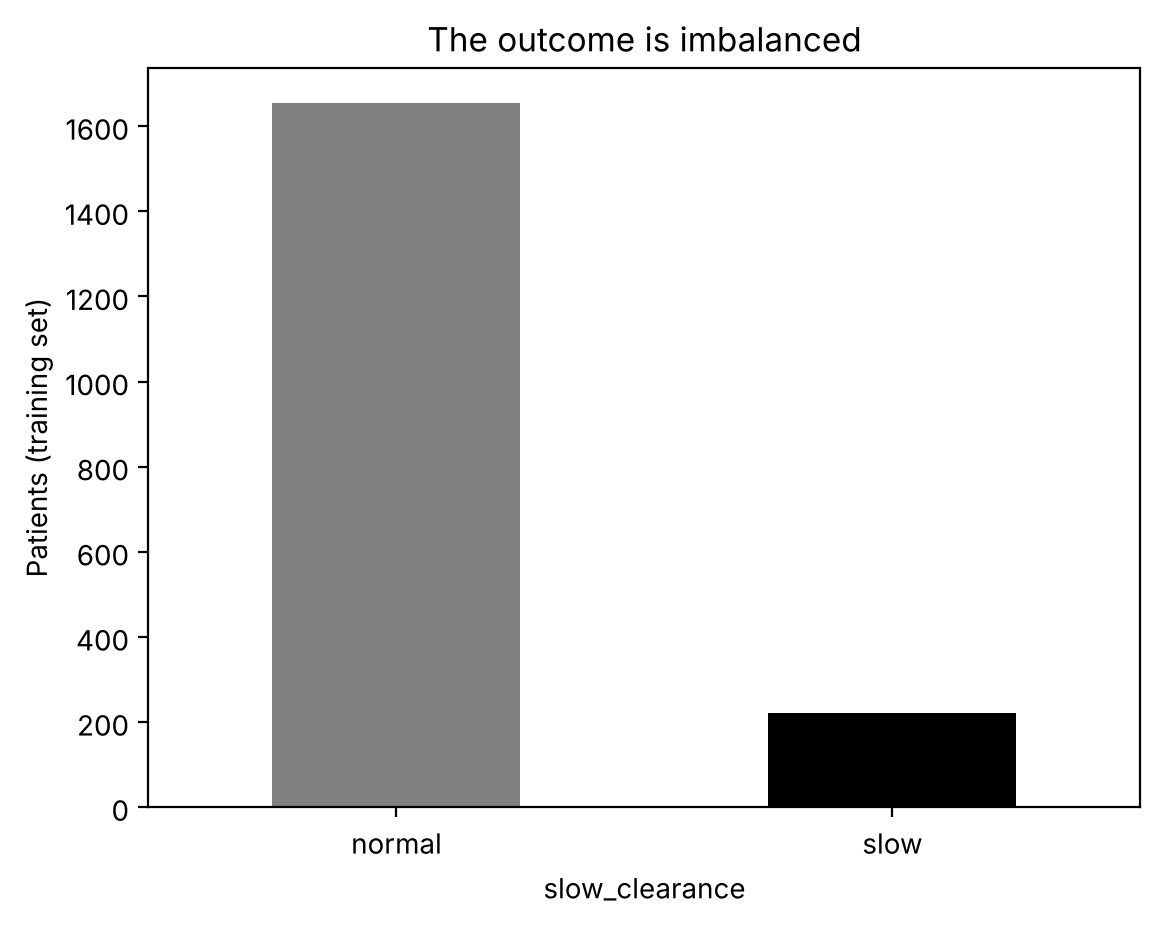

In [13]:
# One table for exploring: TRAINING rows only. The test set stays locked away.
train = X_train.copy()
train[TARGET] = y_train
train["day3_positive"] = clean.loc[X_train.index, "day3_positive"]   # only to show the leakage, never a predictor

def rate_table(by):
    """Number of patients and percentage of slow clearers for each level of a grouping."""
    t = train.groupby(by, observed=True)[TARGET].agg(patients="size", slow="sum", slow_pct="mean")
    t["slow_pct"] = (100 * t["slow_pct"]).round(1)
    return t

print(f"Slow clearance in the training set: {y_train.mean():.1%}")
print(f"Accuracy of a 'model' that says normal for everyone: {1 - y_train.mean():.1%}")

ax = y_train.map({0: "normal", 1: "slow"}).value_counts().plot(kind="bar", color=["grey", "black"])
ax.set_ylabel("Patients (training set)"); ax.set_title("The outcome is imbalanced")
plt.xticks(rotation=0); plt.show()

In [14]:
# Evidence for the leakage decision: day 3 result against the outcome (training rows)
display(pd.crosstab(train["day3_positive"], train[TARGET], margins=True))
print("Slow clearance by day-3 result (%):")
print(rate_table("day3_positive").to_string())

slow_clearance,0,1,All
day3_positive,,,
0,1598,41,1639
1,56,180,236
All,1654,221,1875


Slow clearance by day-3 result (%):
               patients  slow  slow_pct
day3_positive                          
0                  1639    41       2.5
1                   236   180      76.3


In [15]:
# kelch13: every label, then the WHO grouping from the data dictionary
K13_VALIDATED = ["F446I", "N458Y", "C469Y", "M476I", "Y493H", "R539T", "I543T", "P553L",
                 "R561H", "P574L", "C580Y", "R622I", "A675V"]
K13_CANDIDATE = ["P441L", "G449A", "C469F", "A481V", "R515K", "P527H"]

def who_group(kelch13):
    """Turn a column of kelch13 labels into the four WHO groups."""
    return np.select(
        [kelch13 == "wild_type", kelch13.isin(K13_VALIDATED), kelch13.isin(K13_CANDIDATE)],
        ["wild_type", "validated", "candidate"], default="other")

train["k13_group"] = who_group(train["kelch13"])

by_label = rate_table("kelch13").sort_values("patients", ascending=False)
by_label.insert(0, "WHO group", who_group(pd.Series(by_label.index, index=by_label.index)))
display(by_label)
display(rate_table("k13_group"))

,WHO group,patients,slow,slow_pct
kelch13,,,,
wild_type,wild_type,1467,117,8.0
A578S,other,104,6,5.8
C469Y,validated,75,34,45.3
A675V,validated,43,19,44.2
K189T,other,34,0,0.0
P441L,candidate,27,7,25.9
R561H,validated,25,10,40.0
R622I,validated,19,11,57.9
A481V,candidate,17,1,5.9


,patients,slow,slow_pct
k13_group,,,
candidate,80,11,13.8
other,138,6,4.3
validated,190,87,45.8
wild_type,1467,117,8.0


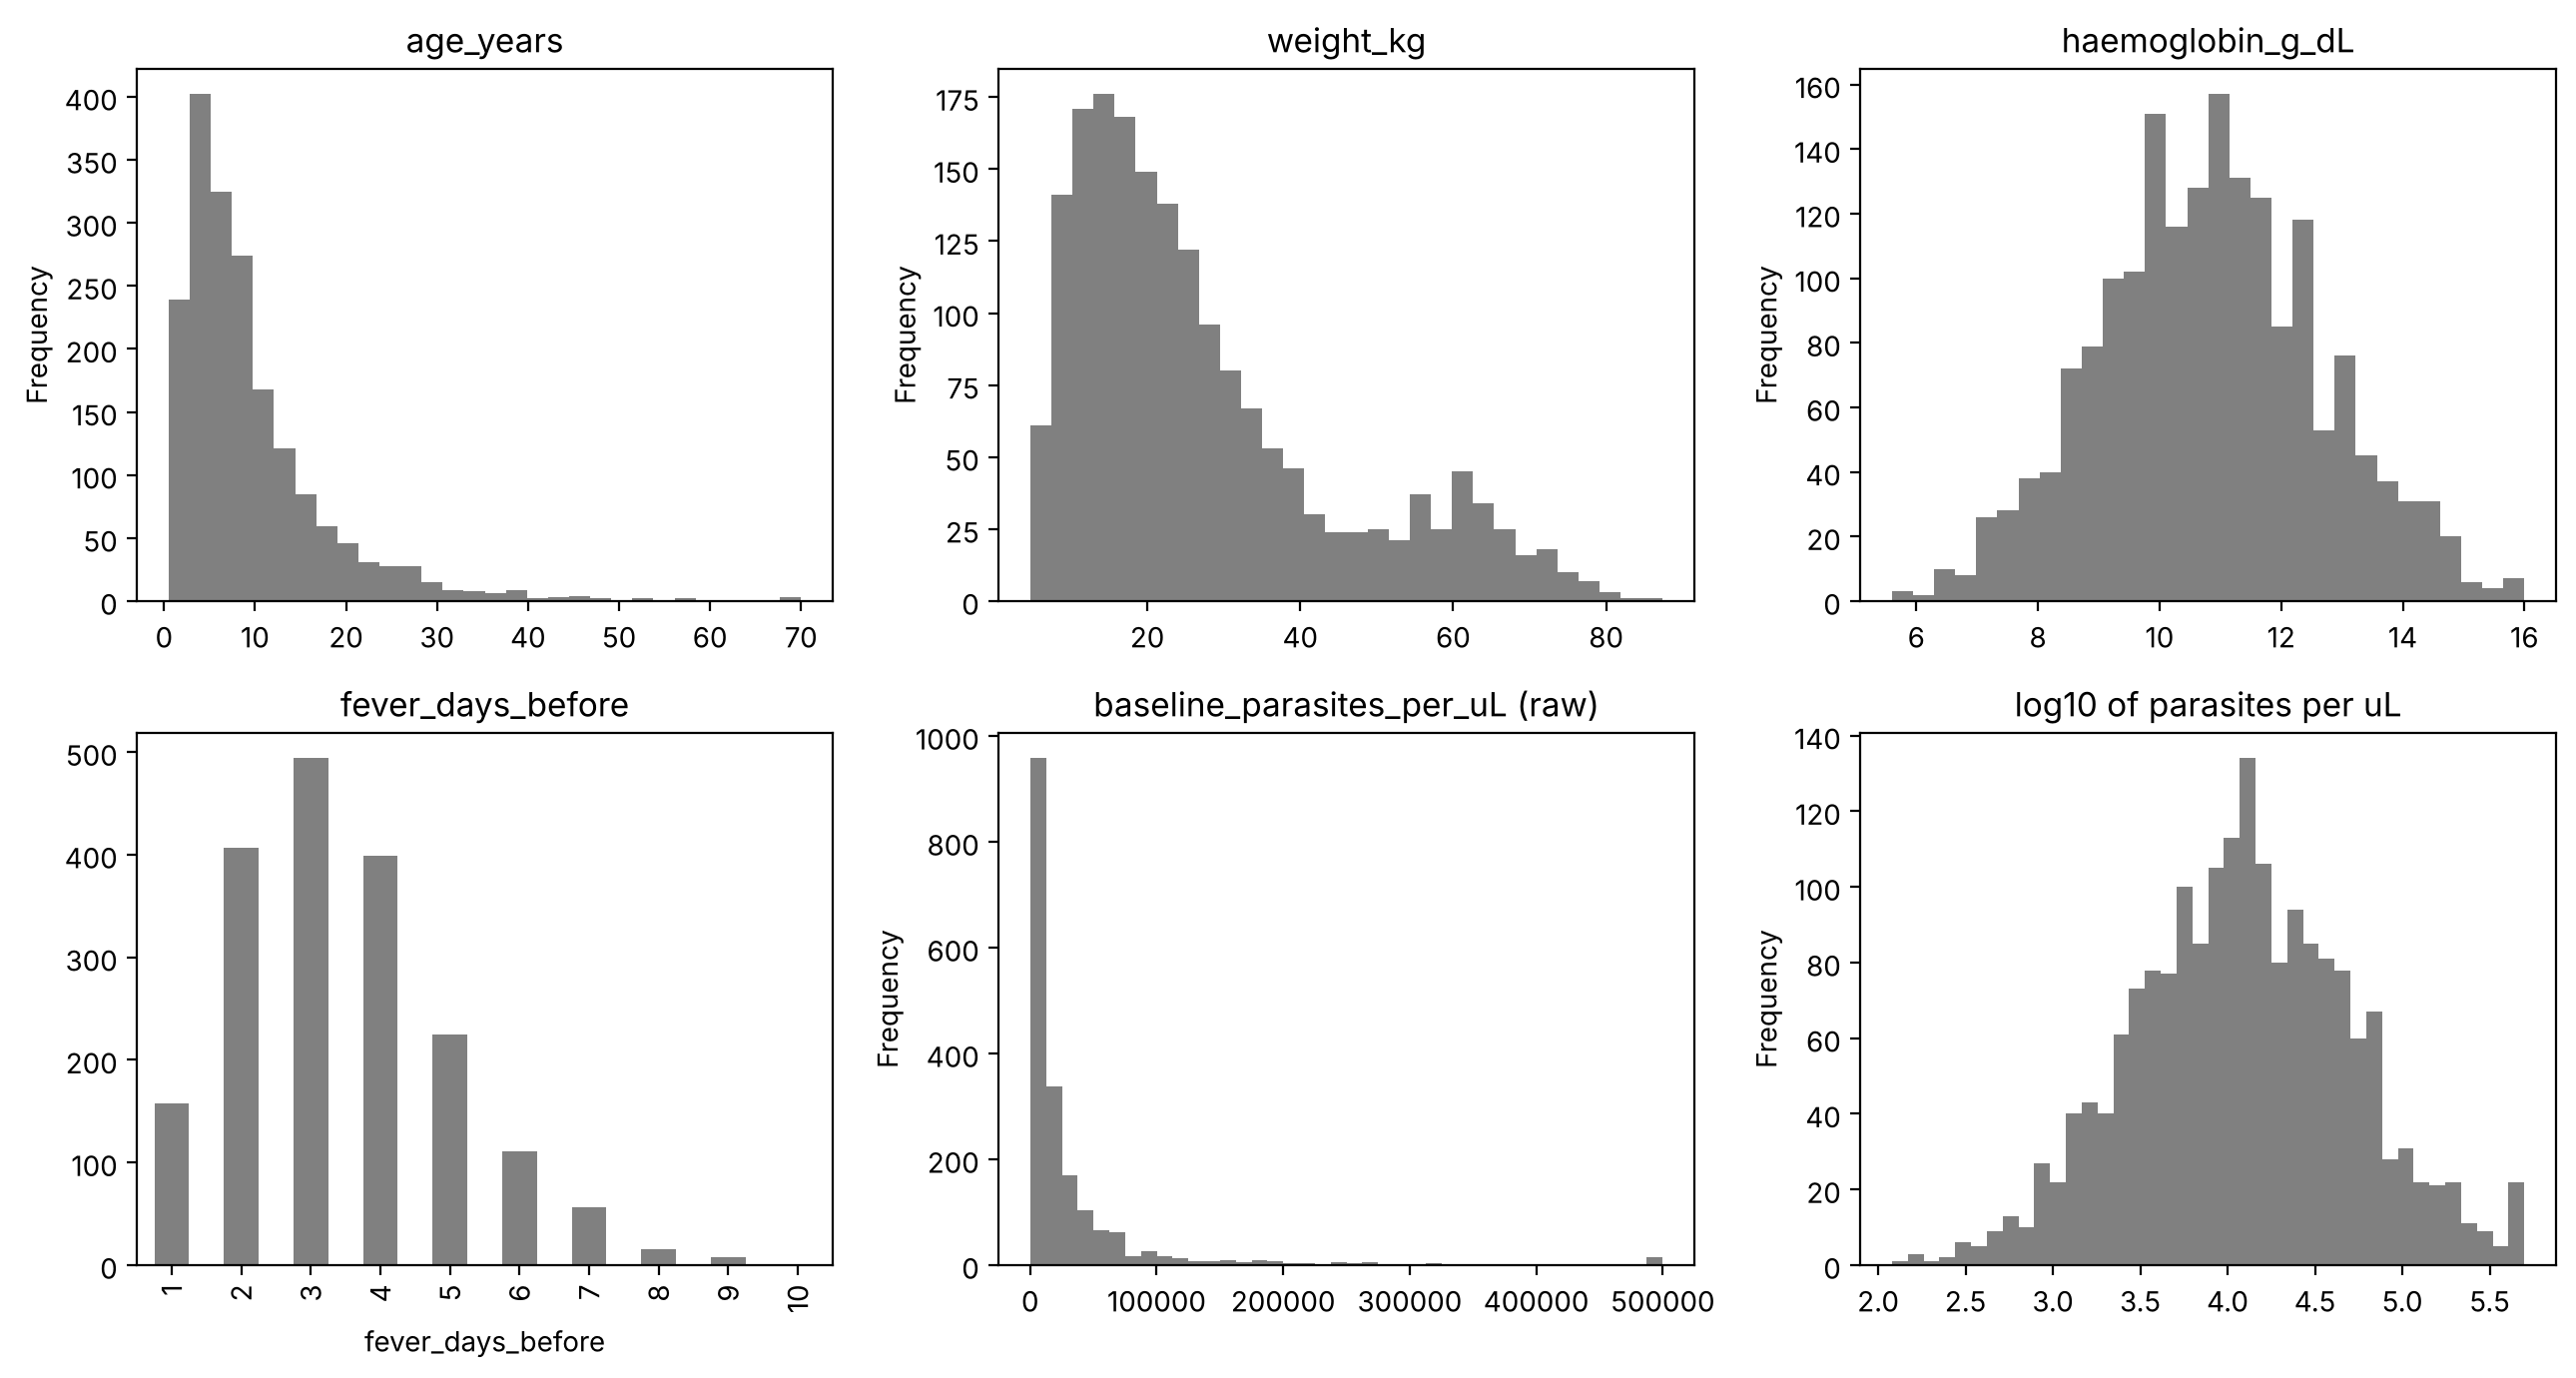

Correlation between age and weight: 0.84


In [16]:
# Shape of the numeric columns. Parasite density is shown raw and on a log scale.
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
train["age_years"].plot(kind="hist", bins=30, ax=axes[0, 0], color="grey", title="age_years")
train["weight_kg"].plot(kind="hist", bins=30, ax=axes[0, 1], color="grey", title="weight_kg")
train["haemoglobin_g_dL"].plot(kind="hist", bins=30, ax=axes[0, 2], color="grey", title="haemoglobin_g_dL")
train["fever_days_before"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 0], color="grey",
                                                            title="fever_days_before")
train["baseline_parasites_per_uL"].plot(kind="hist", bins=40, ax=axes[1, 1], color="grey",
                                        title="baseline_parasites_per_uL (raw)")
np.log10(train["baseline_parasites_per_uL"]).plot(kind="hist", bins=40, ax=axes[1, 2], color="grey",
                                                  title="log10 of parasites per uL")
plt.tight_layout(); plt.show()

print("Correlation between age and weight:", round(train["age_years"].corr(train["weight_kg"]), 2))

,patients,slow,slow_pct
age_band,,,
0.5 to 2,116,24,20.7
over 2 to 5,509,81,15.9
over 5 to 10,642,79,12.3
over 10 to 15,287,23,8.0
over 15,321,14,4.4


,patients,slow,slow_pct
parasite_fifth,,,
lowest,374,28,7.5
low,374,40,10.7
middle,374,42,11.2
high,374,48,12.8
highest,374,63,16.8


,patients,slow,slow_pct
hb_band,,,
under 8,115,17,14.8
8 to 10,502,70,13.9
over 10 to 12,757,85,11.2
over 12,455,45,9.9


,patients,slow,slow_pct
sex,,,
F,975,118,12.1
M,900,103,11.4


,patients,slow,slow_pct
fever_days_before,,,
1,158,16,10.1
2,407,48,11.8
3,494,54,10.9
4,399,55,13.8
5,225,25,11.1
6,111,14,12.6
7,56,7,12.5
8,16,2,12.5
9,8,0,0.0


,patients,slow,slow_pct
crt_K76T,,,
0,1549,175,11.3
1,326,46,14.1


,patients,slow,slow_pct
mdr1_N86Y,,,
0,1487,175,11.8
1,388,46,11.9


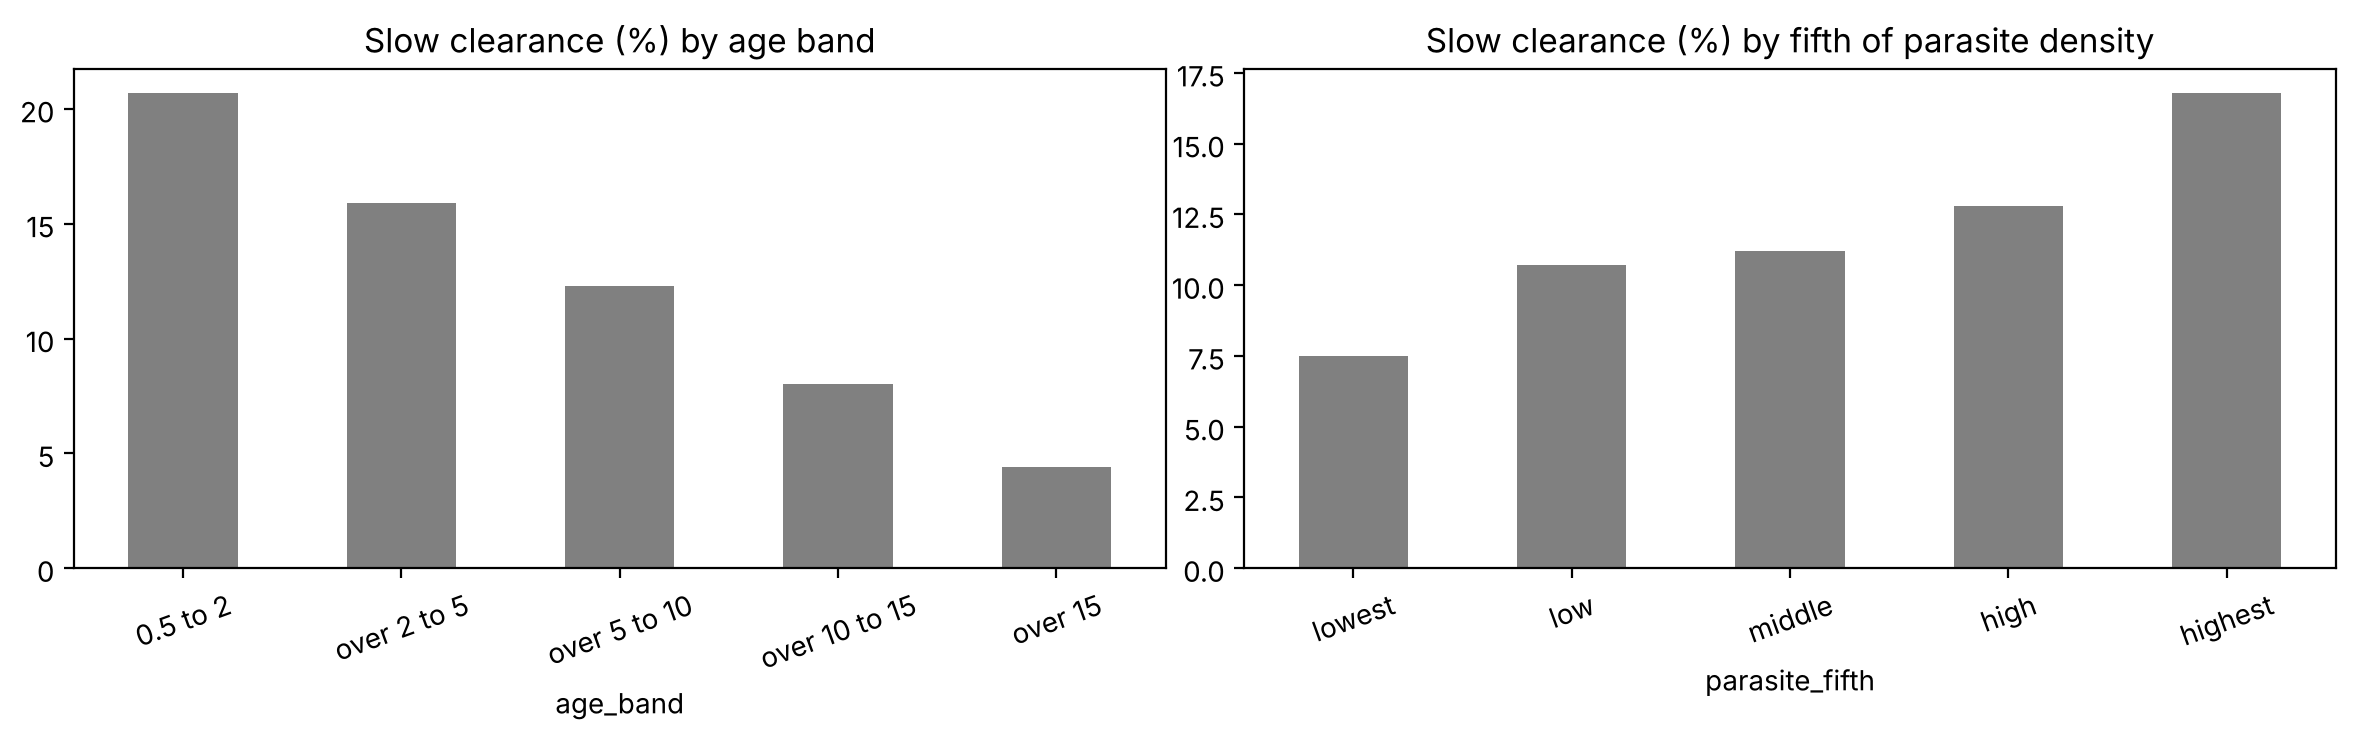

In [17]:
# Slow clearance against each predictor, one at a time
train["age_band"] = pd.cut(train["age_years"], [0, 2, 5, 10, 15, 100],
                           labels=["0.5 to 2", "over 2 to 5", "over 5 to 10", "over 10 to 15", "over 15"])
train["parasite_fifth"] = pd.qcut(train["baseline_parasites_per_uL"], 5,
                                  labels=["lowest", "low", "middle", "high", "highest"])
train["hb_band"] = pd.cut(train["haemoglobin_g_dL"], [0, 8, 10, 12, 20],
                          labels=["under 8", "8 to 10", "over 10 to 12", "over 12"])
REGION = {"Agago": "North", "Lamwo": "North", "Kitgum": "North", "Kabarole": "West", "Hoima": "West",
          "Mubende": "Central", "Tororo": "East", "Busia": "East"}
train["region"] = train["district"].map(REGION)

for col in ["age_band", "parasite_fifth", "hb_band", "sex", "fever_days_before", "crt_K76T", "mdr1_N86Y"]:
    display(rate_table(col))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
rate_table("age_band")["slow_pct"].plot(kind="bar", ax=axes[0], color="grey", title="Slow clearance (%) by age band")
rate_table("parasite_fifth")["slow_pct"].plot(kind="bar", ax=axes[1], color="grey",
                                              title="Slow clearance (%) by fifth of parasite density")
for ax in axes: ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

In [18]:
# Place: slow clearance by district, and which parasites circulate where
display(rate_table(["region", "district"]))
print("Share of each kelch13 group within each district (%):")
display((100 * pd.crosstab(train["district"], train["k13_group"], normalize="index")).round(1))

patients  slow  slow_pct
region  district                          
Central Mubende        248    21       8.5
East    Busia          242    25      10.3
        Tororo         284    17       6.0
North   Agago          280    49      17.5
        Kitgum         196    31      15.8
        Lamwo          194    31      16.0
West    Hoima          195    19       9.7
        Kabarole       236    28      11.9

Share of each kelch13 group within each district (%):


k13_group,candidate,other,validated,wild_type
district,,,,
Agago,7.1,7.9,24.3,60.7
Busia,2.5,6.2,0.8,90.5
Hoima,3.1,11.3,7.7,77.9
Kabarole,7.2,7.2,6.4,79.2
Kitgum,4.6,6.6,17.3,71.4
Lamwo,8.2,4.1,23.2,64.4
Mubende,2.0,8.1,2.0,87.9
Tororo,0.4,7.4,2.1,90.1


Slow clearance (%)


age3,5 or under,over 5 to 15,over 15
k13_group,,,
wild_type,10.5,7.8,3.5
other,8.5,2.7,0.0
candidate,9.5,14.9,16.7
validated,77.0,38.9,8.8


Number of patients behind each percentage


age3,5 or under,over 5 to 15,over 15
k13_group,,,
wild_type,496,714,257
other,47,73,18
candidate,21,47,12
validated,61,95,34


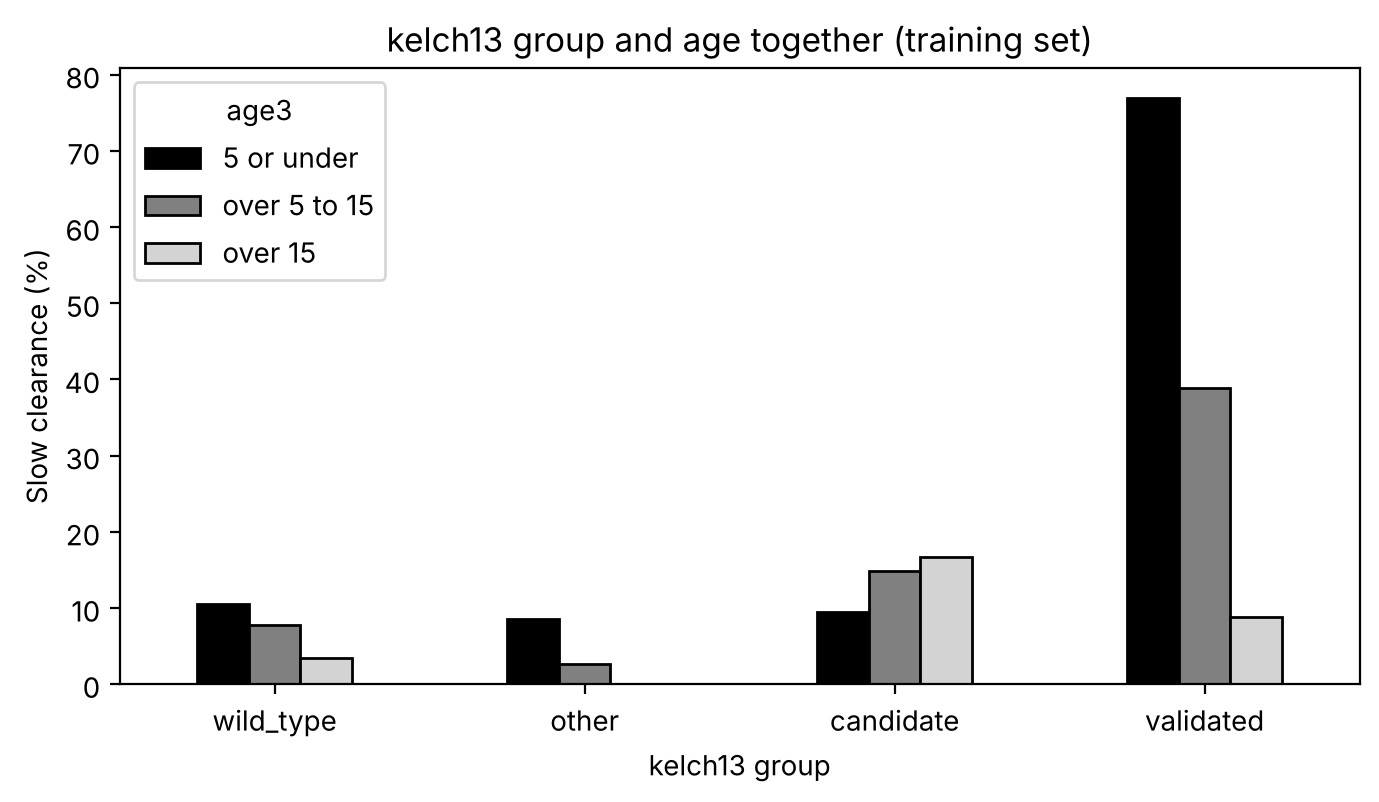

In [19]:
# Does the effect of kelch13 depend on age?
train["age3"] = pd.cut(train["age_years"], [0, 5, 15, 100], labels=["5 or under", "over 5 to 15", "over 15"])
slow_pct = (100 * train.pivot_table(index="k13_group", columns="age3", values=TARGET,
                                    aggfunc="mean", observed=True)).round(1)
counts = pd.crosstab(train["k13_group"], train["age3"])
order = ["wild_type", "other", "candidate", "validated"]
print("Slow clearance (%)"); display(slow_pct.loc[order])
print("Number of patients behind each percentage"); display(counts.loc[order])

slow_pct.loc[order].plot(kind="bar", color=["black", "grey", "lightgrey"], edgecolor="black", figsize=(8, 4))
plt.ylabel("Slow clearance (%)"); plt.xlabel("kelch13 group"); plt.xticks(rotation=0)
plt.title("kelch13 group and age together (training set)"); plt.show()

In [20]:
# Is a missing value itself informative?
for col in ["weight_kg", "haemoglobin_g_dL", "baseline_parasites_per_uL"]:
    is_missing = train[col].isna()
    if is_missing.sum() > 0:
        print(f"{col}: {is_missing.sum()} missing. Slow clearance when missing {train.loc[is_missing, TARGET].mean():.1%}, "
              f"when present {train.loc[~is_missing, TARGET].mean():.1%}")

weight_kg: 61 missing. Slow clearance when missing 16.4%, when present 11.6%
haemoglobin_g_dL: 46 missing. Slow clearance when missing 8.7%, when present 11.9%
baseline_parasites_per_uL: 5 missing. Slow clearance when missing 0.0%, when present 11.8%


### Stage 6. A baseline model

**Where we are:** The exploration is done. Before any feature work, we need something to compare against.

**Why this step:** A baseline is the simplest sensible model. It answers how far we get without any cleverness, and gives each feature work a reference point to beat.

**What we do:** Logistic regression on all ten enrolment columns as they come (raw kelch13 labels, raw parasite density, district). It sits in a pipeline with median imputation and scaling for the numbers and one-hot encoding (handle_unknown="ignore") for the categories. We score it with 5-fold stratified cross-validation, and the same folds are used for every model after it.

**What we decided:** The baseline gives a cross-validated ROC AUC of 0.758 (standard deviation 0.056 across folds) and an average precision of 0.407, against about 0.118 for guessing. Training AUC is 0.783, so the gap is small. We report AUC and average precision and not accuracy, because the outcome is rare. The fold-to-fold standard deviation of about 0.05 is our yardstick for whether a later change is a real improvement.

In [21]:
# The same five folds are used for every model, so that the comparison is fair
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)

def cv_report(name, pipe):
    """Cross-validate a pipeline on the training set. Returns one row of results."""
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    ap = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    train_auc = roc_auc_score(y_train, pipe.fit(X_train, y_train).predict_proba(X_train)[:, 1])
    return {"model": name, "CV AUC (mean)": auc.mean(), "CV AUC (sd)": auc.std(),
            "CV average precision": ap.mean(), "AUC on its own training data": train_auc}

# Baseline: every enrolment column as it comes, no feature work
RAW_NUMERIC = ["age_years", "weight_kg", "fever_days_before", "haemoglobin_g_dL", "baseline_parasites_per_uL"]
RAW_BINARY = ["crt_K76T", "mdr1_N86Y"]
RAW_CATEGORICAL = ["sex", "district", "kelch13"]

baseline = Pipeline([
    ("prepare", ColumnTransformer([
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), RAW_NUMERIC),
        ("binary", SimpleImputer(strategy="most_frequent"), RAW_BINARY),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), RAW_CATEGORICAL)])),
    ("model", LogisticRegression(max_iter=2000)),
])

results = [cv_report("B. baseline: raw columns", baseline)]
print("Reference points: guessing gives AUC 0.50 and average precision about", round(y_train.mean(), 3))
pd.DataFrame(results).round(3)

Reference points: guessing gives AUC 0.50 and average precision about 0.118


,model,CV AUC (mean),CV AUC (sd),CV average precision,AUC on its own training data
0,B. baseline: raw columns,0.758,0.056,0.407,0.783


### Stage 7. Feature work

**Where we are:** We have a baseline score and a list of findings from the exploration.

**Why this step:** To build new columns that present the information in a form the model can use. Each new feature answers something seen in the exploration.

**What we do:** add_features builds five columns from fixed rules: k13_group (the WHO groups), log10_parasites, log_age, region, and validated_x_log_age (the interaction). None of these rules learns from the data, so they cannot leak. They still sit inside the pipeline so that the saved model takes the original enrolment columns. We then compare eight feature sets, each changing one thing from the row above.

**What we decided:**
- WHO groups replace the raw labels. The score stays about the same with far fewer columns, and rare or unseen mutations stop being a problem.
- We use log10 parasite density and log age.
- We keep the interaction. AUC hardly moves, but average precision goes up from 0.421 to 0.448, so it helps rank the highest-risk patients (young children with validated mutations).
- We leave place out. Removing district, or using region instead, did not lower the score (AUC 0.767 to 0.773), because genotype already carries most of what district showed. Without place, the model can also be used in a district outside our data.
- We leave weight out because it repeats age.
- Our chosen set is F7: log age, fever days, haemoglobin, log10 parasites, the interaction, crt_K76T, mdr1_N86Y, sex and the kelch13 group. CV AUC 0.773, average precision 0.459.
- To be fair, the gain over the baseline (about 0.015 AUC) is smaller than the difference between folds. The main gains are a simpler model and better ranking at the top.

In [22]:
def add_features(df):
    """Build new columns from the enrolment columns. Uses fixed rules only, nothing is learned from the data."""
    out = df.copy()
    out["k13_group"] = who_group(out["kelch13"])
    density = out["baseline_parasites_per_uL"]
    out["log10_parasites"] = np.log10(density.where(density > 0))      # a zero or missing value stays missing
    out["log_age"] = np.log(out["age_years"])
    out["region"] = out["district"].map(REGION)
    out["validated_x_log_age"] = (out["k13_group"] == "validated") * out["log_age"]   # the interaction
    return out

def build_pipeline(numeric, binary, categorical, C=1.0):
    """Feature building, preparation and logistic regression in ONE pipeline."""
    prepare = ColumnTransformer([
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
        ("binary", SimpleImputer(strategy="most_frequent"), binary),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical)])
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("prepare", prepare),
        ("model", LogisticRegression(C=C, max_iter=2000)),
    ])

add_features(X_train).head()

,district,age_years,sex,weight_kg,fever_days_before,haemoglobin_g_dL,baseline_parasites_per_uL,kelch13,crt_K76T,mdr1_N86Y,k13_group,log10_parasites,log_age,region,validated_x_log_age
1337,Mubende,3.3,F,11.5,5,10.8,44625.0,wild_type,0,1,wild_type,4.649578,1.193922,Central,0.0
22,Kabarole,25.9,F,77.6,3,10.4,24204.0,A578S,0,0,other,4.383887,3.254243,West,0.0
1348,Mubende,1.4,M,7.4,1,11.6,10122.0,wild_type,1,1,wild_type,4.005266,0.336472,Central,0.0
18,Tororo,4.3,F,16.1,5,8.5,9728.0,wild_type,0,0,wild_type,3.988024,1.458615,East,0.0
106,Mubende,7.8,F,23.2,2,10.4,40313.0,wild_type,0,0,wild_type,4.605445,2.054124,Central,0.0


In [23]:
# Each feature set changes ONE thing compared with the row above it
BIN = ["crt_K76T", "mdr1_N86Y"]
FEATURE_SETS = {
    "F1. WHO groups instead of raw kelch13 labels": (
        ["age_years", "weight_kg", "fever_days_before", "haemoglobin_g_dL", "baseline_parasites_per_uL"],
        BIN, ["sex", "district", "k13_group"]),
    "F2. F1 with log10 parasite density": (
        ["age_years", "weight_kg", "fever_days_before", "haemoglobin_g_dL", "log10_parasites"],
        BIN, ["sex", "district", "k13_group"]),
    "F3. F2 with log age": (
        ["log_age", "weight_kg", "fever_days_before", "haemoglobin_g_dL", "log10_parasites"],
        BIN, ["sex", "district", "k13_group"]),
    "F4. F3 plus validated x age interaction": (
        ["log_age", "weight_kg", "fever_days_before", "haemoglobin_g_dL", "log10_parasites", "validated_x_log_age"],
        BIN, ["sex", "district", "k13_group"]),
    "F5. F4 with region instead of district": (
        ["log_age", "weight_kg", "fever_days_before", "haemoglobin_g_dL", "log10_parasites", "validated_x_log_age"],
        BIN, ["sex", "region", "k13_group"]),
    "F6. F4 with no place at all": (
        ["log_age", "weight_kg", "fever_days_before", "haemoglobin_g_dL", "log10_parasites", "validated_x_log_age"],
        BIN, ["sex", "k13_group"]),
    "F7. F6 without weight": (
        ["log_age", "fever_days_before", "haemoglobin_g_dL", "log10_parasites", "validated_x_log_age"],
        BIN, ["sex", "k13_group"]),
    "F8. lean: age, parasites, kelch13 group, interaction": (
        ["log_age", "log10_parasites", "validated_x_log_age"], [], ["k13_group"]),
}

results = results[:1]                                   # keep the baseline row, drop older runs of this cell
for name, (numeric, binary, categorical) in FEATURE_SETS.items():
    results.append(cv_report(name, build_pipeline(numeric, binary, categorical)))

comparison = pd.DataFrame(results).set_index("model").round(3)
comparison

,CV AUC (mean),CV AUC (sd),CV average precision,AUC on its own training data
model,,,,
B. baseline: raw columns,0.758,0.056,0.407,0.783
F1. WHO groups instead of raw kelch13 labels,0.754,0.050,0.420,0.776
F2. F1 with log10 parasite density,0.767,0.050,0.413,0.787
F3. F2 with log age,0.764,0.051,0.421,0.785
F4. F3 plus validated x age interaction,0.767,0.054,0.448,0.791
F5. F4 with region instead of district,0.769,0.048,0.454,0.785
F6. F4 with no place at all,0.773,0.048,0.460,0.785
F7. F6 without weight,0.773,0.050,0.459,0.785
"F8. lean: age, parasites, kelch13 group, interaction",0.769,0.046,0.462,0.776


### Stage 8. Pipeline and cross-validation

**Where we are:** The feature set is chosen.

**Why this step:** All preparation has to be learned inside each training fold, so that cross-validation stays honest. If not, the validation fold leaks into its own preparation and the score looks better than it is.

**What we do:** One pipeline: features (add_features), then prepare (numbers: median imputation then scaling; binary columns: most-frequent imputation; categories: one-hot), then the logistic regression model. It is scored with the same 5 stratified folds.

**What we decided:** The fold AUCs were 0.818, 0.816, 0.728, 0.804 and 0.698 (mean 0.773, standard deviation 0.050). Two folds are lower. With about 44 slow clearers per fold, this much spread is expected, and it tells us to expect a fairly wide range on the test set too. We keep this pipeline.

In [24]:
# Decision 3: the chosen feature set (reasons in the Stage 7 cell above)
FINAL_SET = "F7"

final_name = [name for name in FEATURE_SETS if name.startswith(FINAL_SET)][0]
NUMERIC, BINARY, CATEGORICAL = FEATURE_SETS[final_name]
print("Chosen:", final_name)

chosen_pipe = build_pipeline(NUMERIC, BINARY, CATEGORICAL)
fold_auc = cross_val_score(chosen_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print("AUC in each of the five folds:", fold_auc.round(3))
print(f"Mean {fold_auc.mean():.3f}, standard deviation {fold_auc.std():.3f}")
chosen_pipe

Chosen: F7. F6 without weight
AUC in each of the five folds: [0.818 0.816 0.728 0.804 0.698]
Mean 0.773, standard deviation 0.050


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prepare', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...x7fea330b8680>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictiona

### Stage 10. Overfitting check and tuning (done before Stage 9)

**Where we are:** The pipeline is fixed. We now tune it and check for overfitting.

**Why this step:** To prevent a model that learns the quirks of its training data so well that it scores well on the training data and worse on new data. C also changes the predicted probabilities, so it has to be settled here, before the cut-off.

**What we do:** A grid search over C from 0.01 to 10 with the same folds, comparing the training-fold and validation-fold AUC. As an extra check we also cross-validate a random forest, which can find interactions by itself.

**What we decided:**
- Validation AUC goes up until C = 1 (0.773) and is then flat. The gap between training and validation is only about 0.01 for every C, so there is very little overfitting. This is what we expected with about 13 prepared columns and 221 slow clearers.
- We use C = 1, the value with the best validation AUC.
- The random forest scored lower (CV AUC 0.741) while reaching 0.937 on its own training data, which is clear overfitting. It found nothing our features had missed, so we stay with logistic regression, which is also easier to explain to the programme.
- From the coefficients: a validated mutation has the biggest positive effect, and the interaction is negative (−0.58), so the extra risk from a validated mutation falls with age. Higher parasite density raises the risk. Sex, fever days and mdr1_N86Y are close to zero.
- The risk table puts this in plain numbers. For an otherwise typical patient with a validated mutation, the predicted risk is 92% at age 1, 55% at 5, 27% at 12 and 6% at 40. With wild type it is 16% at age 1 and under 8% from age 5.

,C,AUC on training folds,AUC on validation folds,gap
0,0.01,0.762,0.755,0.006
1,0.03,0.767,0.759,0.007
2,0.10,0.775,0.766,0.009
3,0.30,0.781,0.771,0.010
4,1.00,0.786,0.773,0.013
5,3.00,0.787,0.773,0.014
6,10.00,0.787,0.772,0.015


C with the highest validation AUC: 1


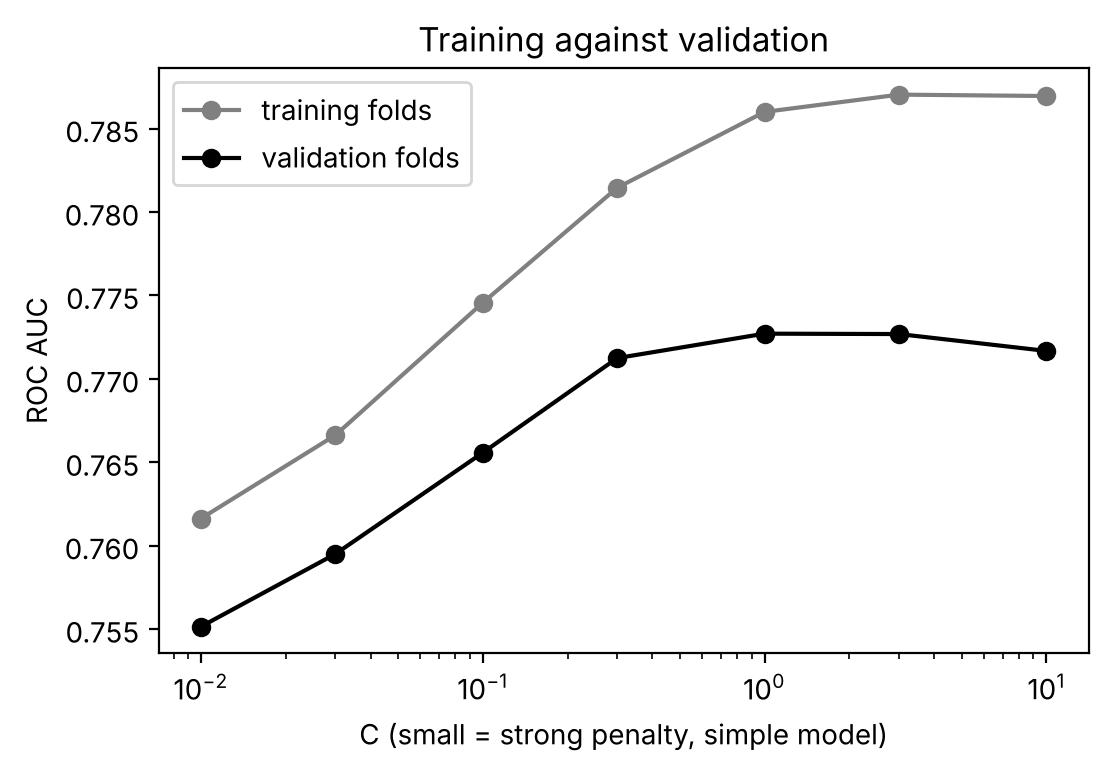

In [25]:
# Overfitting check and tuning: try several strengths of regularisation (C)
grid = GridSearchCV(
    build_pipeline(NUMERIC, BINARY, CATEGORICAL),
    param_grid={"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    cv=cv, scoring="roc_auc", return_train_score=True)
grid.fit(X_train, y_train)

tuning = pd.DataFrame({
    "C": grid.cv_results_["param_model__C"],
    "AUC on training folds": grid.cv_results_["mean_train_score"],
    "AUC on validation folds": grid.cv_results_["mean_test_score"],
})
tuning["gap"] = tuning["AUC on training folds"] - tuning["AUC on validation folds"]
display(tuning.round(3))
print("C with the highest validation AUC:", grid.best_params_["model__C"])

plt.figure(figsize=(6, 3.8))
plt.plot(tuning["C"], tuning["AUC on training folds"], marker="o", color="grey", label="training folds")
plt.plot(tuning["C"], tuning["AUC on validation folds"], marker="o", color="black", label="validation folds")
plt.xscale("log"); plt.xlabel("C (small = strong penalty, simple model)"); plt.ylabel("ROC AUC")
plt.legend(); plt.title("Training against validation"); plt.show()

In [26]:
# Sense check: does a flexible model that finds interactions by itself do better?
from sklearn.ensemble import RandomForestClassifier

forest = Pipeline([
    ("features", FunctionTransformer(add_features)),
    ("prepare", ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"),
         ["age_years", "weight_kg", "fever_days_before", "haemoglobin_g_dL", "log10_parasites", "crt_K76T", "mdr1_N86Y"]),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), ["sex", "district", "k13_group"])])),
    ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=SPLIT_SEED)),
])
pd.DataFrame([cv_report("Random forest (sense check)", forest)]).set_index("model").round(3)

,CV AUC (mean),CV AUC (sd),CV average precision,AUC on its own training data
model,,,,
Random forest (sense check),0.741,0.057,0.441,0.937


In [27]:
# Decision 4: C with the best validation AUC (Stage 10)
FINAL_C = grid.best_params_["model__C"]

final_model = build_pipeline(NUMERIC, BINARY, CATEGORICAL, C=FINAL_C)
final_model.fit(X_train, y_train)            # fitted on the training set only

# What did the model learn? One coefficient per prepared column.
coefficients = pd.DataFrame({
    "prepared column": final_model.named_steps["prepare"].get_feature_names_out(),
    "coefficient": final_model.named_steps["model"].coef_[0],
})
coefficients["odds ratio"] = np.exp(coefficients["coefficient"])
coefficients.sort_values("coefficient", ascending=False).round(2)

,prepared column,coefficient,odds ratio
11,categorical__k13_group_validated,2.99,19.86
3,numeric__log10_parasites,0.41,1.51
5,binary__crt_K76T,0.19,1.21
1,numeric__fever_days_before,0.05,1.05
8,categorical__sex_M,0.02,1.02
6,binary__mdr1_N86Y,-0.02,0.98
7,categorical__sex_F,-0.04,0.96
2,numeric__haemoglobin_g_dL,-0.21,0.81
9,categorical__k13_group_candidate,-0.38,0.68
0,numeric__log_age,-0.41,0.67


In [28]:
# The model in plain numbers: predicted chance of slow clearance for an otherwise typical patient
typical = {col: (X_train[col].median() if pd.api.types.is_numeric_dtype(X_train[col]) else X_train[col].mode()[0])
           for col in X_train.columns}
examples = {"wild_type": "wild_type", "other": "A578S", "candidate": "P441L", "validated": "C469Y"}

rows = []
for age in [1, 3, 5, 8, 12, 20, 40]:
    for group, label in examples.items():
        rows.append({**typical, "age_years": age, "kelch13": label, "group": group})
grid_patients = pd.DataFrame(rows)
grid_patients["risk_pct"] = 100 * final_model.predict_proba(grid_patients[X_train.columns])[:, 1]
grid_patients.pivot(index="age_years", columns="group", values="risk_pct")[list(examples)].round(1)

group,wild_type,other,candidate,validated
age_years,,,,
1,15.7,11.5,28.3,92.0
3,9.6,6.9,18.4,71.3
5,7.6,5.4,14.8,55.0
8,6.1,4.3,12.0,38.9
12,5.0,3.5,10.0,26.6
20,3.9,2.7,7.9,15.1
40,2.8,1.9,5.7,6.3


### Stage 9. The outcome rate, and the choice of cut-off (done after Stage 10)

**Where we are:** The model and C are fixed. We now choose above what probability an infection is flagged.

**Why this step:** The model outputs a probability. To act, someone must decide above what probability we flag, based on the outcome rate and the performance (recall and precision). With only about 12% slow, the default of 0.5 is too high: at 0.5 the model finds only a quarter of slow clearers.

**What we do:** We use cross-validated predictions on the training set, so each patient's risk comes from a model that did not see them. Then we lay out recall, precision and the share flagged at ten cut-offs. The test set is not touched.

**What we decided:** We chose a cut-off of 0.15, because:
- For this user a flag leads to a cheap action, like adding the sample to a sequencing batch or watching a site more closely. A false alarm costs little, so we accept lower precision to find more slow clearers.
- At 0.15 (training, cross-validated) recall is 52%, precision 35%, and 17% of infections are flagged. Going down to 0.10 would raise recall to 68%, but 35% of infections would be flagged and three in four flags would be false alarms. Going up to 0.20 or higher drops recall below half.
- The histogram shows that no cut-off can catch most of the remaining slow clearers. They sit at low predicted risk among the normal clearers, and most of them are wild type.
- The cut-off was fixed before the test set was opened.

,flagged (%),recall: slow clearers found (%),precision: flagged that are truly slow (%),specificity (%),found (TP),missed (FN),false alarms (FP)
cut-off,,,,,,,
0.05,71.2,91.0,15.1,31.4,201,20,1134
0.08,46.9,78.3,19.7,57.3,173,48,707
0.10,34.5,67.9,23.2,70.0,150,71,497
0.12,26.0,62.9,28.5,78.9,139,82,349
0.15,17.3,52.0,35.4,87.3,115,106,210
0.20,11.2,42.5,44.8,93.0,94,127,116
0.25,8.8,37.6,50.3,95.0,83,138,82
0.30,7.5,34.4,53.9,96.1,76,145,65
0.40,5.4,30.8,67.3,98.0,68,153,33


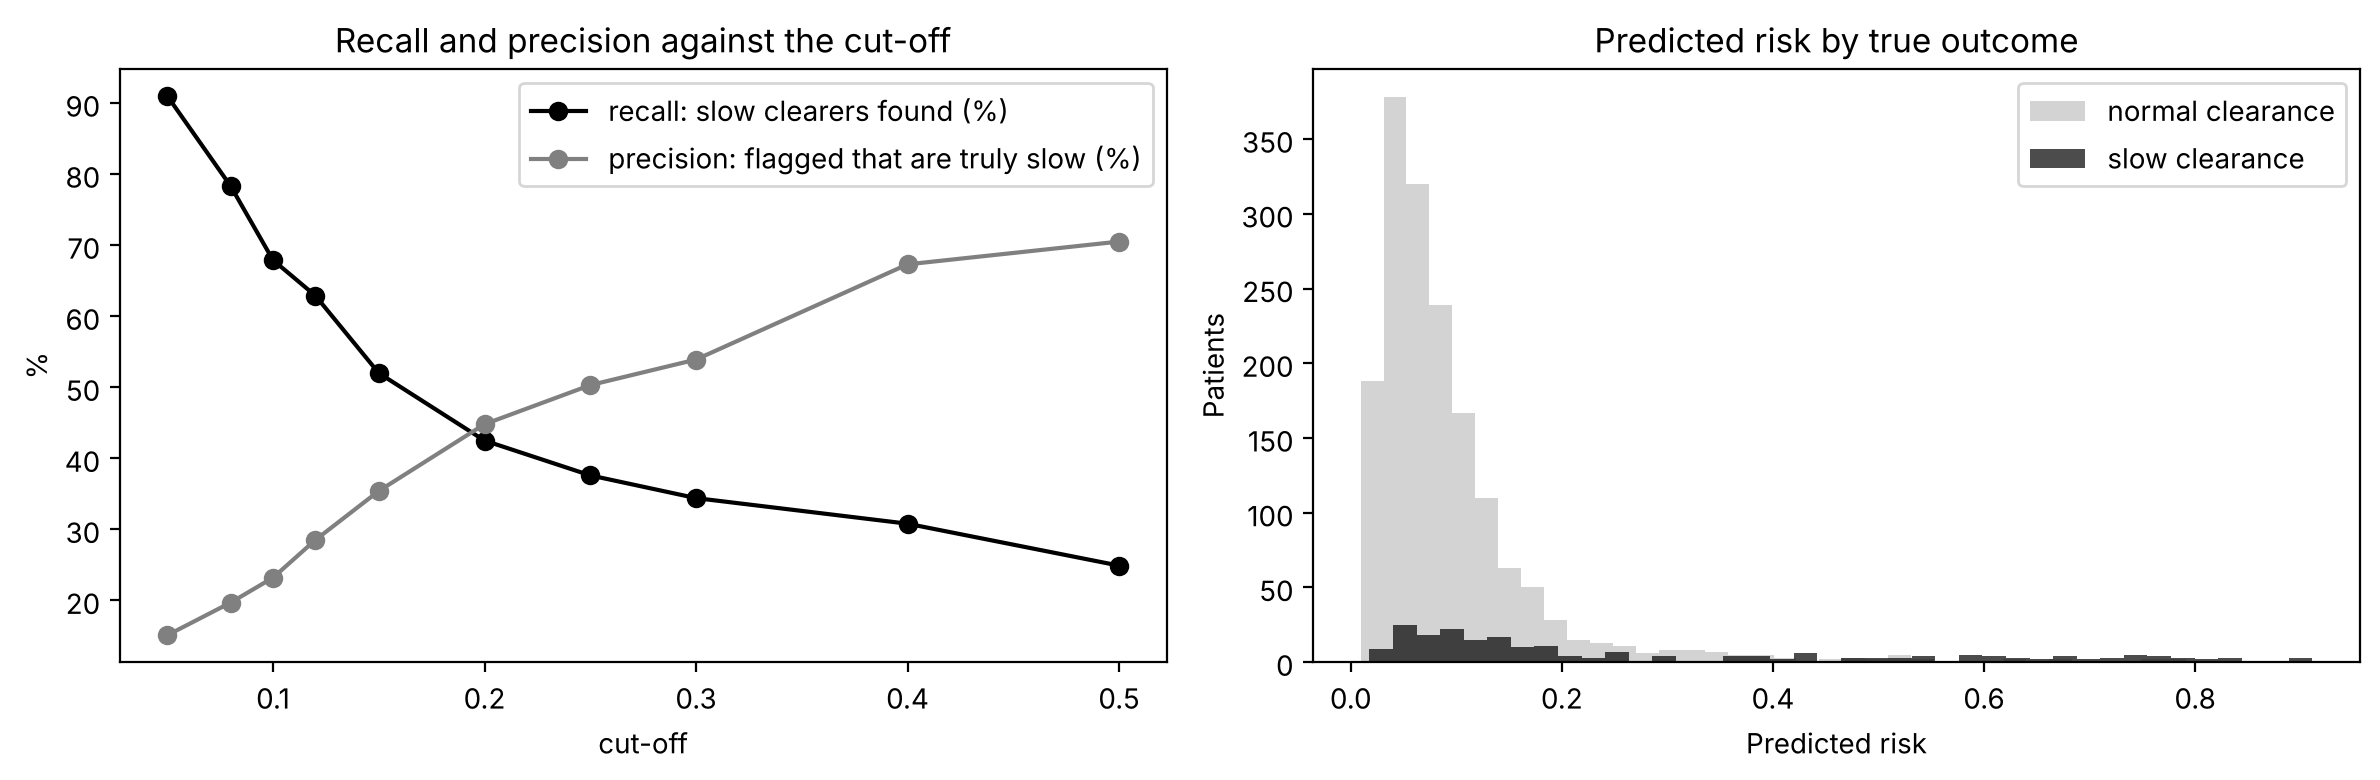

In [29]:
# Cut-off: use predictions made for each training patient by a model that never saw that patient
cv_risk = cross_val_predict(build_pipeline(NUMERIC, BINARY, CATEGORICAL, C=FINAL_C),
                            X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in [0.05, 0.08, 0.10, 0.12, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    flagged = (cv_risk >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, flagged).ravel()
    rows.append({"cut-off": t, "flagged (%)": 100 * flagged.mean(),
                 "recall: slow clearers found (%)": 100 * tp / (tp + fn),
                 "precision: flagged that are truly slow (%)": 100 * tp / max(tp + fp, 1),
                 "specificity (%)": 100 * tn / (tn + fp),
                 "found (TP)": tp, "missed (FN)": fn, "false alarms (FP)": fp})
cutoffs = pd.DataFrame(rows).set_index("cut-off").round(1)
display(cutoffs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cutoffs[["recall: slow clearers found (%)", "precision: flagged that are truly slow (%)"]].plot(
    ax=axes[0], color=["black", "grey"], marker="o", title="Recall and precision against the cut-off")
axes[0].set_ylabel("%")
axes[1].hist(cv_risk[y_train == 0], bins=40, color="lightgrey", label="normal clearance")
axes[1].hist(cv_risk[y_train == 1], bins=40, color="black", alpha=0.7, label="slow clearance")
axes[1].set_xlabel("Predicted risk"); axes[1].set_ylabel("Patients"); axes[1].set_title("Predicted risk by true outcome")
axes[1].legend(); plt.tight_layout(); plt.show()

In [30]:
# Decision 5: the cut-off (reasons in the Stage 9 cell above)
THRESHOLD = 0.15

flagged = (cv_risk >= THRESHOLD).astype(int)
print(f"At a cut-off of {THRESHOLD} (cross-validated, training set):")
print(f"  recall    {recall_score(y_train, flagged):.1%} of slow clearers are flagged")
print(f"  precision {precision_score(y_train, flagged):.1%} of flagged infections are truly slow")
print(f"  flagged   {flagged.mean():.1%} of all infections")

At a cut-off of 0.15 (cross-validated, training set):
  recall    52.0% of slow clearers are flagged
  precision 35.4% of flagged infections are truly slow
  flagged   17.3% of all infections


### Stage 11. Final test, once

**Where we are:** Every decision is now fixed: the cleaning rules, feature set F7, C = 1 and the cut-off of 0.15. The test set is opened for the first and only time.

**Why this step:** The test patients played no part in any choice, so the result is an honest estimate of performance on new patients. If we looked at the result and then went back to improve the model, the test set would become part of training and its result would no longer be honest.

**What we do:** We predict for the 625 test patients and report the ROC AUC with a 2,000-sample bootstrap interval, the average precision, the confusion matrix at 0.15, the ROC, precision-recall and calibration plots, results by region, age and genotype group, and a comparison with waiting for the day-3 film.

**What we decided (results):**
- The test ROC AUC is 0.781 (95% interval 0.722 to 0.840). This is close to the cross-validated 0.773, so our cross-validation was honest and the model is not overfitted. The interval is wide because there are only 73 slow clearers.
- Average precision is 0.461, against 0.117 for guessing.
- At 0.15, recall is 49.3% (36 of 73 slow clearers flagged), precision 33.0% (36 of 109 flags truly slow) and specificity 86.8%. Accuracy is 82.4%, which is below the 88.3% from saying "normal" for everyone. That is expected, because that rule finds no slow clearers at all.
- The baseline scored 0.745 on the same test set. Our model is ahead, but by less than the width of the interval.
- On the calibration plot the points lie close to the diagonal, so the predicted risks can be read roughly as real chances.
- Where and in whom: the North has the highest observed rate (18.2%) and the highest predicted risk (14.9%), even though place is not in the model. Young children have the highest rate (16.0% observed, 15.9% predicted). 84% of validated infections were flagged but only 8% of wild-type ones, and wild type made up 37 of the 73 slow clearers.
- Waiting for the day-3 film would give recall of 86% and precision of 76%. So our enrolment model cannot replace clearance monitoring. Its value is being early and showing which groups and places to watch.

In [31]:
# THE FINAL TEST, run once after every decision above was fixed
test_risk = final_model.predict_proba(X_test)[:, 1]
test_flag = (test_risk >= THRESHOLD).astype(int)

test_auc = roc_auc_score(y_test, test_risk)
test_ap = average_precision_score(y_test, test_risk)

# How sure are we? Re-draw the test set 2,000 times (bootstrap) and see how much the AUC moves
rng = np.random.default_rng(SPLIT_SEED)
y_arr = y_test.to_numpy()
boot = []
for _ in range(2000):
    pick = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[pick].min() != y_arr[pick].max():          # need both classes to compute an AUC
        boot.append(roc_auc_score(y_arr[pick], test_risk[pick]))
low, high = np.percentile(boot, [2.5, 97.5])

tn, fp, fn, tp = confusion_matrix(y_test, test_flag).ravel()
print(f"Test set: {len(y_test)} patients, {int(y_test.sum())} slow clearers")
print(f"ROC AUC            : {test_auc:.3f}   (95% bootstrap interval {low:.3f} to {high:.3f})")
print(f"Average precision  : {test_ap:.3f}   (guessing would give about {y_test.mean():.3f})")
print(f"At cut-off {THRESHOLD}:")
print(f"  recall (sensitivity) : {tp / (tp + fn):.1%}   ({tp} of {tp + fn} slow clearers flagged)")
print(f"  precision (PPV)      : {tp / (tp + fp):.1%}   ({tp} of {tp + fp} flagged infections truly slow)")
print(f"  specificity          : {tn / (tn + fp):.1%}")
print(f"  accuracy             : {accuracy_score(y_test, test_flag):.1%}   (saying normal for everyone: {1 - y_test.mean():.1%})")

baseline.fit(X_train, y_train)
print(f"Baseline model on the same test set, ROC AUC: {roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1]):.3f}")

Test set: 625 patients, 73 slow clearers
ROC AUC            : 0.781   (95% bootstrap interval 0.722 to 0.840)
Average precision  : 0.461   (guessing would give about 0.117)
At cut-off 0.15:
  recall (sensitivity) : 49.3%   (36 of 73 slow clearers flagged)
  precision (PPV)      : 33.0%   (36 of 109 flagged infections truly slow)
  specificity          : 86.8%
  accuracy             : 82.4%   (saying normal for everyone: 88.3%)
Baseline model on the same test set, ROC AUC: 0.745


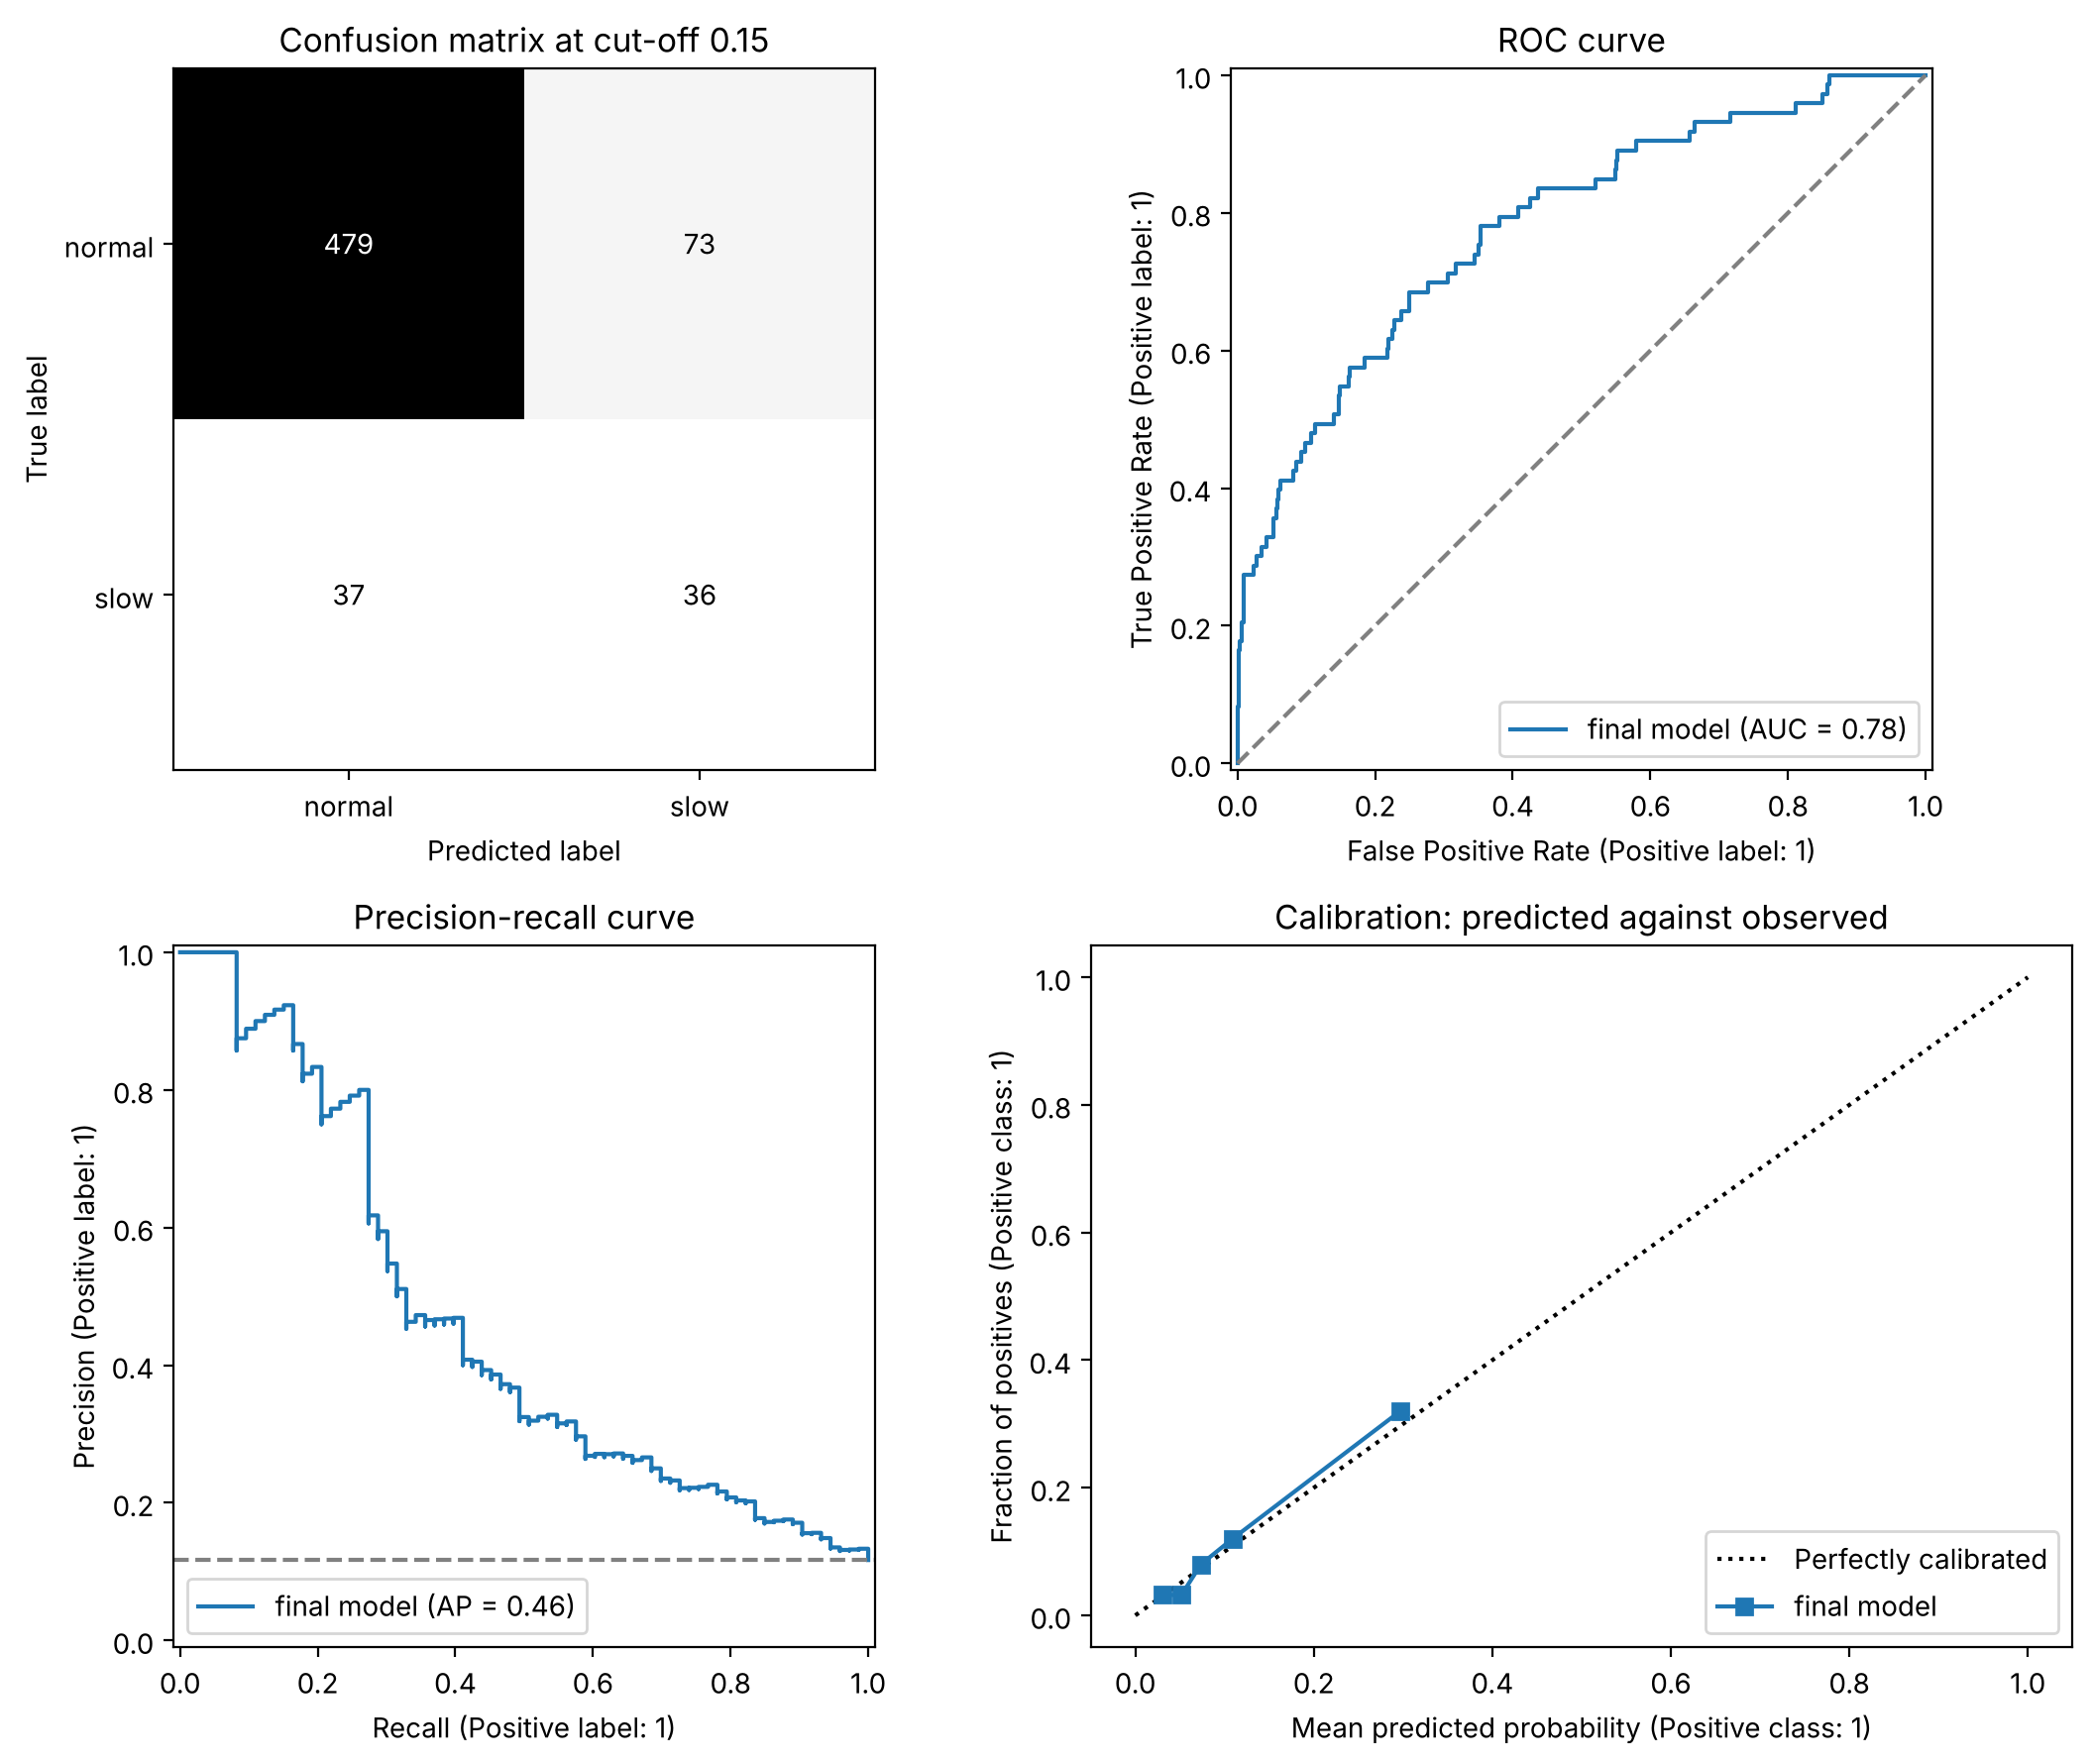

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(y_test, test_flag, display_labels=["normal", "slow"],
                                        cmap="Greys", colorbar=False, ax=axes[0, 0])
axes[0, 0].set_title(f"Confusion matrix at cut-off {THRESHOLD}")
RocCurveDisplay.from_predictions(y_test, test_risk, ax=axes[0, 1], name="final model")
axes[0, 1].plot([0, 1], [0, 1], linestyle="--", color="grey"); axes[0, 1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, test_risk, ax=axes[1, 0], name="final model")
axes[1, 0].axhline(y_test.mean(), linestyle="--", color="grey"); axes[1, 0].set_title("Precision-recall curve")
CalibrationDisplay.from_predictions(y_test, test_risk, n_bins=5, strategy="quantile", ax=axes[1, 1],
                                    name="final model")
axes[1, 1].set_title("Calibration: predicted against observed")
plt.tight_layout(); plt.show()

In [33]:
# Where and in whom? Observed and predicted slow clearance in the test set, by region and by age
test_view = add_features(X_test)
test_view["observed"] = y_test
test_view["predicted_risk"] = test_risk
test_view["flagged"] = test_flag
test_view["age3"] = pd.cut(test_view["age_years"], [0, 5, 15, 100], labels=["5 or under", "over 5 to 15", "over 15"])

for by in ["region", "age3", "k13_group"]:
    t = test_view.groupby(by, observed=True).agg(patients=("observed", "size"), slow=("observed", "sum"),
                                                 observed_pct=("observed", "mean"),
                                                 mean_predicted_pct=("predicted_risk", "mean"),
                                                 flagged_pct=("flagged", "mean"))
    t[["observed_pct", "mean_predicted_pct", "flagged_pct"]] = (100 * t[["observed_pct", "mean_predicted_pct", "flagged_pct"]]).round(1)
    display(t)

,patients,slow,observed_pct,mean_predicted_pct,flagged_pct
region,,,,,
Central,91,7,7.7,8.9,12.1
East,166,13,7.8,8.2,9.6
North,214,39,18.2,14.9,25.2
West,154,14,9.1,10.8,18.2


,patients,slow,observed_pct,mean_predicted_pct,flagged_pct
age3,,,,,
5 or under,213,34,16.0,15.9,27.7
over 5 to 15,304,31,10.2,10.1,14.8
over 15,108,8,7.4,5.3,4.6


,patients,slow,observed_pct,mean_predicted_pct,flagged_pct
k13_group,,,,,
candidate,35,6,17.1,16.3,54.3
other,26,3,11.5,6.7,3.8
validated,56,27,48.2,40.4,83.9
wild_type,508,37,7.3,7.9,8.3


In [34]:
# For discussion only: how does predicting at enrolment compare with simply waiting for the day-3 blood film?
day3_test = clean.loc[X_test.index, "day3_positive"]
print("Waiting for day 3 : recall {:.1%}, precision {:.1%}".format(
    recall_score(y_test, day3_test), precision_score(y_test, day3_test)))
print("Our model at enrolment (cut-off {}): recall {:.1%}, precision {:.1%}".format(
    THRESHOLD, recall_score(y_test, test_flag), precision_score(y_test, test_flag)))

Waiting for day 3 : recall 86.3%, precision 75.9%
Our model at enrolment (cut-off 0.15): recall 49.3%, precision 33.0%


### Stage 12. Save the model, write a model card, and answer the question

**Where we are:** The test is done. Nothing in the model changes from here.

**Why this step:** A model that lives only inside a notebook cannot be used by anyone. Saving it to a file lets someone else load it and make predictions, and the model card tells them what it is for and what its limits are.

**What we do:** We save the fitted pipeline with joblib, together with the cut-off and the settings, reload it to check the predictions are the same, and collect the facts for the model card.

**What we decided:** The model is saved as G06_ProblemC_model.joblib, and the reloaded copy gives identical predictions. To use it elsewhere, apply_cleaning_rules, add_features, who_group, the two WHO lists and REGION must be defined first, and new data must be cleaned with the same rules.

In [35]:
# Save the fitted pipeline together with the facts a user needs
MODEL_FILE = f"{GROUP_ID.strip().upper()}_Problem{problem}_model.joblib"
joblib.dump({"pipeline": final_model, "threshold": THRESHOLD, "features": final_name,
             "C": FINAL_C, "group_fingerprint": GROUP_FINGERPRINT}, MODEL_FILE)

# Check that the saved file gives the same predictions as the model in memory
loaded = joblib.load(MODEL_FILE)
same = np.allclose(loaded["pipeline"].predict_proba(X_test)[:, 1], test_risk)
print("Saved to", MODEL_FILE, "| reloaded model gives identical predictions:", same)

# Facts for the model card
pd.Series({
    "Outcome": TARGET, "Predicted at": "enrolment, before the first dose",
    "Training patients": len(X_train), "Slow clearers in training": int(y_train.sum()),
    "Feature set": final_name, "Model": f"logistic regression, C = {FINAL_C}",
    "Cross-validated AUC (training)": round(fold_auc.mean(), 3),
    "Test patients": len(X_test), "Slow clearers in test": int(y_test.sum()),
    "Test ROC AUC": f"{test_auc:.3f} (95% interval {low:.3f} to {high:.3f})",
    "Test average precision": round(test_ap, 3),
    "Cut-off": THRESHOLD, "Test recall at cut-off": f"{tp / (tp + fn):.1%}",
    "Test precision at cut-off": f"{tp / (tp + fp):.1%}",
    "Cleaning rules": f"Hb: {HB_RULE}; zero parasites: {ZERO_PARASITE_RULE}; 500,000: {CAP_500K_RULE}",
}, name="value").to_frame()

Saved to G06_ProblemC_model.joblib | reloaded model gives identical predictions: True


,value
Outcome,slow_clearance
Predicted at,"enrolment, before the first dose"
Training patients,1875
Slow clearers in training,221
Feature set,F7. F6 without weight
Model,"logistic regression, C = 1"
Cross-validated AUC (training),0.773
Test patients,625
Slow clearers in test,73
Test ROC AUC,0.781 (95% interval 0.722 to 0.840)


### Model card

| Item | Details |
|---|---|
| Model name and version | G06 Problem C slow-clearance model, version 1 (November 2026) |
| Intended use and user | The national malaria control programme, for surveillance: to see in which places and groups of patients slow clearance (artemisinin partial resistance) is likely, and to decide which samples or sites to follow up |
| Not intended for | Treatment decisions for single patients; drugs other than artemether-lumefantrine; other countries or periods; replacing day-3 or clearance half-life monitoring |
| Outcome predicted, and when | slow_clearance (clearance half-life over 5 hours), predicted at enrolment before the first dose |
| Data used for training | Simulated teaching data: 1,875 patients from eight Ugandan districts (221 slow clearers, 11.8%). Group sample fingerprint 98C9-85DA |
| Cleaning rules | Exact duplicates removed; wild-type spellings merged; haemoglobin above 18 divided by 10; parasite density of 0 set to missing; 500,000 kept; missing values filled with the training median |
| Predictors | Log age, fever days, haemoglobin, log10 parasite density, sex, kelch13 WHO group (wild type, other, candidate, validated), validated × log age, crt_K76T, mdr1_N86Y |
| Predictors left out on purpose, and why | day3_positive (recorded after enrolment, so leakage); patient_id (only a label); district (added nothing once genotype was in, and would stop the model being used in new districts); weight (repeats age) |
| Model type and settings | Logistic regression, C = 1, in a scikit-learn pipeline with median imputation, scaling and one-hot encoding |
| Performance on the test set | 625 patients, 73 slow clearers. ROC AUC 0.781 (95% interval 0.722 to 0.840); average precision 0.461. At cut-off 0.15: recall 49.3%, precision 33.0%, specificity 86.8%. Predicted risks well calibrated |
| Cut-off, and why it was chosen | 0.15. A flag leads to a cheap follow-up, so we accept more false alarms to find about half of slow clearers. Chosen from cross-validated training predictions, before the test |
| How to use the saved file | joblib.load("G06_ProblemC_model.joblib") gives the pipeline and the cut-off. Define apply_cleaning_rules, add_features, who_group, the WHO lists and REGION first, clean new data with the same rules, then call predict_proba |
| Limitations and risks | Simulated data; one study and eight districts; only 73 slow clearers in the test set; rare mutations have few patients; most wild-type slow clearers are missed; genotyping takes time in practice; WHO marker lists change over time |
| What is needed before real use | Testing on real patients from other sites and years; agreement on what action a flag leads to; regular updating of the kelch13 lists; checking performance after it is put to use |

---
## 6. Conclusions

**The answer to the question, for the user of your model** (in plain language, quoting your results):

Partly yes. With only what is known at enrolment, the model can rank infections by their risk of slow clearance fairly well (test ROC AUC 0.78). It clearly shows where and in whom the risk is concentrated: young children whose parasites carry a WHO-validated kelch13 mutation, and the northern districts (Agago, Lamwo, Kitgum), where these mutations are most common. For a typical child aged 1 with a validated mutation, the model predicts a 92% chance of slow clearance, against about 6% for a 40-year-old with the same mutation.

At our cut-off of 0.15, the model flags about one infection in six and finds about half of all slow clearers (49%). About one in three flagged infections is truly slow (33%). It cannot find the slow clearers whose parasites are wild type, and they are about half of all slow clearers. For the programme, the model is useful for deciding which places, age groups and samples to watch. It is not for confirming resistance in a single patient.

**How well does your model work on new data, and how sure are you?**

On the 625 test patients the ROC AUC was 0.781, very close to the cross-validated 0.773. So the model works on new patients from the same population and is not overfitted. We are only moderately sure of the exact value: the 95% bootstrap interval runs from 0.722 to 0.840, because only 73 test patients were slow clearers. The model beat the raw-column baseline on the same test set (0.745), but by less than this interval, so most of what we gained is a simpler model that is easier to explain. The predicted risks matched the observed rates well on the calibration plot. Waiting for the day-3 blood film finds slow clearers much better (recall 86%, precision 76%), so the value of our model is that it is early and explains the risk, not that it is more accurate.

**Limitations, and what would need to happen before this model could be used for real:**

- The data are simulated and come from one study in eight districts. The model would have to be tested on real patients from other sites and later years.
- More than half of slow clearers carry wild-type parasites and are mostly missed. Finding them would need other causes or markers of slow clearance.
- Several kelch13 mutations have only a handful of patients, and the WHO lists of validated and candidate markers change, so the grouping would need regular updating.
- Genotype results take days or weeks in practice, so the model suits surveillance, not same-day decisions.
- The cut-off assumes a flag leads to a cheap follow-up. The programme would need to agree what action a flag leads to and set the cut-off to match what it can handle.
- Precision depends on how common slow clearance is. Where it is rarer, more flags would be false alarms.
- Once in use, its performance should be checked and the model refitted as resistance patterns change.

---
## 7. Contribution statement

| Member (name) | Registration number | What I led | What I reviewed or checked |
|---|---|---|---|
| Momodou Jallow | 2026/HD07/23463X | Stages 9 to 12: tuning and overfitting check, cut-off, final test, saving the model and the model card | Aheebwa |
| Nabakooza Hilda | 2026/HD07/23484U | Stages 5 to 8: exploration, baseline, feature work, pipeline and cross-validation | Jallow |
| Aheebwa Ronnie | 2026/HD07/23443U | Stages 1 to 4: problem and data dictionary, first look and cleaning rules, leakage check, train/test split | Hilda |

---
## 8. Declarations (one per member)

### Member 1
1. **Name and registration number:** Momodou Jallow, 2026/HD07/23463X
2. **Group number, problem and group fingerprint:** G06, Problem C, 98C9-85DA
3. **I have read through all the code in this notebook, and it represents what our group intended to do. (yes / no):**
4. **I can explain and defend any part of this notebook, not only the parts I led. (yes / no):**
5. **The written parts I contributed are in my own words, without AI tools. (yes / no):**
6. **Use of AI tools:** I used AI tools for *(write "none", or describe exactly what you used them for, and where)*:
7. I understand that I may be asked to complete a **short timed test or oral check** on any part of this work. **(yes / no):**
8. **Date:**

### Member 2
1. **Name and registration number:** Nabakooza Hilda, 2026/HD07/23484U
2. **Group number, problem and group fingerprint:** G06, Problem C, 98C9-85DA
3. **I have read through all the code in this notebook, and it represents what our group intended to do. (yes / no):**
4. **I can explain and defend any part of this notebook, not only the parts I led. (yes / no):**
5. **The written parts I contributed are in my own words, without AI tools. (yes / no):**
6. **Use of AI tools:** I used AI tools for *(write "none", or describe exactly what you used them for, and where)*:
7. I understand that I may be asked to complete a **short timed test or oral check** on any part of this work. **(yes / no):**
8. **Date:**

### Member 3
1. **Name and registration number:** Aheebwa Ronnie, 2026/HD07/23443U
2. **Group number, problem and group fingerprint:** G06, Problem C, 98C9-85DA
3. **I have read through all the code in this notebook, and it represents what our group intended to do. (yes / no):** yes
4. **I can explain and defend any part of this notebook, not only the parts I led. (yes / no):** yes
5. **The written parts I contributed are in my own words, without AI tools. (yes / no):** yes (Though the AI was used for correspondence and review of my responses and check for correctness of my responses)
6. **Use of AI tools:** I used AI tools for *(write "none", or describe exactly what you used them for, and where)*: I used Claude for the following: giving a brief overview of the assignment, explaining and overview of the variables and the data problems, and a pre-modelling briefing (PDF) for the group, drafting the complext code i couldnt comprehend for now "but with full explanations and responsible use (I understand the code written with deep explanation)", polishing the gramma, to avoid typos, checking for mistakes in code and responses - majorly used to draft the complex code and  review the personally written reponses.

7. I understand that I may be asked to complete a **short timed test or oral check** on any part of this work. **(yes / no):** yes
8. **Date:** 23 November 2026